# When to Replace a Slow Leader: Election-Timeout Trade-offs in a Raft-Style Cluster

**Summary.** Distributed databases such as etcd elect one leader server. Followers start a new election if no heartbeat arrives within an *election timeout*. A short timeout replaces a bad leader quickly but can trigger needless elections when the network is jittery. A long timeout avoids false alarms but prolongs real outages. This notebook builds a discrete-event simulation of a five-node, timing-level Raft-style cluster to find which timeout minimises total downtime, and how the best value moves as network jitter grows.

**What this notebook contains.** The model parameters, the event engine, separate random-number streams, random network delays, Raft-style voting and elections, node health (a healthy / slow / failed chain, two ways for a node to be slow, and recovery), the **false-suspicion check**, the **downtime meter**, election classes, outage lengths, **replications with 95% confidence intervals**, and the **main sweep** in section 6.3 (7 timeouts x 3 jitter levels x 2 slow models, 30 replications of 10 simulated minutes each). Section 5 contains **21 automated checks**, each shown with an `assert` or a tolerance test. Sections 6.4 to 6.6 add a Monte Carlo convergence study, a three-node versus five-node comparison under three delay distributions, and a one-factor-at-a-time sensitivity analysis.

**Reproducibility.** The notebook runs top to bottom with Runtime -> Run all, with no manual steps. Every random stream is derived from master seed 42 (set in section 4.1), so repeated runs on any machine give identical numbers; only the wall-clock time differs. All times are in milliseconds (ms) unless stated otherwise.

## 2. Problem and question

**Situation.** A cluster of five servers keeps data consistent by electing one leader. The leader sends a *heartbeat* to every follower every 100 ms (etcd default). Each follower runs a countdown, the *election timeout* (etcd default 1000 ms). If the countdown ends before a heartbeat arrives, the follower starts an election. While no working leader exists, the service is down. A leader can be healthy, slow (alive but late) or failed, and network delays vary.

**Question.** Which election-timeout setting minimises total service downtime when leaders can be healthy, slow or failed, and how does the best setting change as network jitter increases?

**Scope.** Timing only: heartbeats, timers, elections and node health. No log replication, no stored data, no real network.

## 3. Model, assumptions and equations

**Heartbeats.** The leader of term $\tau$ sends heartbeat $k$ at time $t_k = t_0 + k\,h$, where $h = 100$ ms. It reaches follower $i$ at $t_k + D_{k,i}$, where $D_{k,i}$ is the one-way message delay (ms).

**Message delay.** Every message gets an independent delay

$$D = d + J + E,$$

where $d = 5$ ms is a fixed propagation part, $J \ge 0$ is **network jitter** with mean $m$, and $E \ge 0$ is the **slow-node extra delay**. $E = 0$ unless the *sender* is in the Slow state.

- *Jitter, constant:* $J = 0$.
- *Jitter, exponential* (inverse-transform method): $J = -m \ln(1-U)$, with $U \sim \mathrm{Uniform}[0,1)$.
- *Jitter, lognormal:* $J = \exp(\mu + \sigma Z)$, with $Z \sim N(0,1)$ and $\mu = \ln m - \sigma^2/2$, so that $E[J] = m$.
- *Jitter, Pareto-I (X3):* $J = x_m/(1-U)^{1/\alpha}$, where $\alpha > 1$ and $x_m = m(\alpha-1)/\alpha$. This gives a finite theoretical mean $E[J]=m$ and a power-law tail.
- *Slow extra delay:* $E = -s \ln(1-U')$, exponential with mean $s$ = `slow_extra_delay_ms`. $E$ and $J$ have **separate parameters and separate random streams**, because "network jitter versus a slow node" is the question of the project.

Because delays are independent, messages can arrive out of order.

**Election timer.** A follower restarts its timer whenever it accepts a heartbeat or grants a vote. The timer length is drawn uniformly, $T_i \sim \mathrm{Uniform}[T,\; 2T]$, where $T$ is the base election timeout. If the timer ends first, the node starts an election.

**Election rules (simplified Raft).**
1. Every node has a *term* (a number that only goes up). A node that sees a higher term adopts it and becomes a follower.
2. A node whose timer ends becomes a *candidate*: it adds 1 to its term, votes for itself, restarts its timer and asks the other nodes for votes.
3. A node grants a vote only if the request's term equals its own term and it has not already voted for someone else in that term. So each node votes **at most once per term**.
4. A candidate that gets a majority, $\lfloor n/2 \rfloor + 1 = 3$ of 5 votes (its own included), becomes leader and sends a heartbeat immediately.
5. A heartbeat from a term at least as high as the node's own is accepted (and a candidate steps down). A heartbeat from a lower term is ignored.

**Safety invariant.** At most one leader can exist in any one term (election safety). The code asserts this every time a node becomes leader.

**Node health (Markov chain).** Every node has its own chain with states $\{H, S, F\}$ (healthy, slow, failed). The chain moves in steps of $\Delta = 1000$ ms:

$$\Pr(X_{n+1}=j \mid X_n=i) = P_{ij}, \qquad \sum_j P_{ij} = 1 .$$

The long-run fraction of time in each state is the stationary distribution $\pi$, which solves $\pi P = \pi$ with $\sum_j \pi_j = 1$. The average stay in state $i$ is $1/(1-P_{ii})$ steps. Because $\Delta = 1$ s, every health spell lasts at least 1 s. The next state is drawn by the *discrete inverse-transform method*: draw $U$ and pick the first state whose cumulative probability exceeds $U$.

What each state does:
- **Healthy:** normal.
- **Slow, default mode ("late messages"):** every message the node *sends* gets the extra delay $E$. Its heartbeat loop and timers run on schedule, and what it receives is not delayed.
- **Slow, optional mode ("late heartbeats", A14, off by default):** a slow leader waits $h + W$ before its next heartbeat, with $W \sim \mathrm{Exponential}(s)$. Its heartbeats then get no extra per-message delay (the wait replaces it); its vote requests and vote replies still get $E$ as above.
- **Failed:** the node ignores every event and sends nothing. Messages that arrive at it are lost.
- **Recovery (Failed to Healthy or Slow):** the node returns as a **follower**, even if it was the leader. It keeps its term and its vote (the disk survived the crash) and starts a fresh random timer.

**Downtime (the metric).** With $w$ = `slow_weight` (0.5),

$$\text{downtime} = \int_0^{L} \Big( \mathbf{1}\{\text{no working leader}\} + w\,\mathbf{1}\{\text{working leader is Slow}\} \Big)\, dt .$$

$w = 0$ ignores slow time and $w = 1$ treats a slow leader like no leader. "Working leader" is made precise in assumption A15.

**Monte Carlo.** With $n$ independent replications, the 95% confidence interval for a mean is $\bar{x} \pm t_{0.975,\,n-1}\, s/\sqrt{n}$.

**Concepts applied**

| Part of the model | Concept |
|---|---|
| Future event list, clock jumping from event to event (section 4.2) | Discrete-event simulation (next-event time advance) |
| Constant, exponential, lognormal and Pareto delays, slow extra delay, discrete draws of the next health state (sections 4.2 and 4.3) | Input modelling and random variate generation |
| Healthy / slow / failed chain, its $\pi$ and its checks (sections 4.3 and 5) | Markov chains (DTMC) |
| Many seeds, mean and 95% CI | Monte Carlo and the law of large numbers |

**Assumptions**
- A1. Timing-level model only: no log replication (a deliberate scope choice).
- A2. Node 0 is the leader of term 1 at time 0 (having voted for itself), if it is not failed at that moment.
- A3. One-way delay = 5 ms fixed + random jitter (+ slow extra delay, A11); delays are independent, so messages can be reordered and are never lost (except messages that arrive at a failed node). Jitter levels in `JITTER_LEVELS_MS` are provisional. For Pareto jitter, `pareto_alpha` must exceed 1 so its mean is finite.
- A4. Each timer draw is $\mathrm{Uniform}[T, 2T]$. This is this project's own modelling choice. The Raft paper only says election timeouts are random from a fixed interval, so it is not the source of the $T$ to $2T$ range.
- A5. Health spells last at least one step, 1 s. Shorter hiccups are treated as network jitter (decided).
- A6. Voting follows the Raft rules above but without the log up-to-date check. There are no heartbeat replies: an out-of-date leader learns about a newer term from the vote requests and heartbeats it receives.
- A7. The hooks `crash`, `health_events` and `initial_health` set a node's health by hand. They are used in the checks and in section 6.1. In the full model the chain (`health_chain_on=True`) does this.
- A8. Each node's health at time 0 is drawn from the stationary distribution $\pi$, so the chain needs no warm-up.
- A9. Each node's health steps happen at times $u_i + k\Delta$ with $u_i \sim \mathrm{Uniform}[0, \Delta)$, so nodes do not all change state at the same instant.
- A10. A node that leaves the Failed state comes back as a follower with its term and vote unchanged and a fresh random timer, even if it was the leader. This means the disk survived the crash (real Raft saves the term and vote to disk). A recovering node therefore never votes twice in one term.
- A11. A Slow node's extra delay applies **only when it sends** a message, not when it receives one. $E$ is exponential with mean `slow_extra_delay_ms`, drawn separately from the jitter $J$. (In the optional mode A14 it applies to vote requests and vote replies only.)
- A12. Each purpose and each node has its own random-number stream (timer, delay, slow extra delay, slow heartbeat wait, health). Changing one input (for example the jitter level) does not change the random numbers used for the others.
- A13. Downtime counts no-leader time with weight 1 and slow-leader time with weight `slow_weight` = 0.5 (a parameter, to be swept later).
- A14. **Optional mode `slow_heartbeat_wait` (off by default; for the X5 sensitivity study).** While a node is Slow and leader, the gap before its next heartbeat is $h + W$ with $W \sim \mathrm{Exponential}(s)$, $s$ = `slow_extra_delay_ms`, instead of exactly $h$. $W$ is drawn when the previous heartbeat is sent, using the node's health at that moment, from its own random stream. In this mode heartbeats get no per-message extra delay, and A11 still applies to vote requests and vote replies. With the mode off nothing changes.
- A15. **Working leader (decided).** At every moment take the node that is in the Leader role and has the **highest term** (the newest-term leader). If there is none, or it is Failed, there is **no working leader** (weight 1). If it is Slow the weight is $w$ = `slow_weight`; if it is Healthy the weight is 0. A failed leader keeps its Leader role until it recovers (A10) or is replaced, so its outage counts as downtime until a new leader is elected. A deposed leader that has not heard about the new term yet is ignored, because the newest-term leader decides.
- A16. The downtime meter starts at time 0 with no warm-up (A2 and A8 give a defined start) and stops at the end of the run. An outage still going on at the end counts in the downtime but not in the list of completed outage lengths (it is cut off).
- A17. An election is classified when its candidate times out: **unnecessary (false suspicion)** if a Healthy working leader exists, **slow-leader replacement** if the working leader is Slow, **needed** if there is no working leader. Replications are independent seeds $0, 1, \dots, n-1$, the same seeds in every cell (A12). Cells are compared with Welch's two-sample interval, not a paired one, because the measured correlation between cells was weak.

## 4. Implementation

### 4.1 Packages and parameters
All settings live in one frozen `Params` object. Times are in **ms**.

In [100]:
# Overall notebook runtime tracking: start
from datetime import datetime
from time import perf_counter

_notebook_start_datetime = datetime.now().astimezone()
_notebook_start_counter = perf_counter()
print('Notebook execution started:', _notebook_start_datetime.strftime('%Y-%m-%d %H:%M:%S %Z (UTC%z)'))

Notebook execution started: 2026-11-26 04:50:00 UTC (UTC+0000)


In [101]:
# Colab already has these packages; the line just makes the notebook self-contained.
!pip install -q numpy scipy matplotlib

import heapq
import itertools
from dataclasses import dataclass, replace

from time import perf_counter      # to time the sweep

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats      # only for the t-table value in confidence intervals

SEED = 42                    # master random seed
SIM_DURATION_MS = 60_000.0   # simulated time per run in the checks: 60 s
RUN_DURATION_MS = 600_000.0  # simulated time per run in the experiments of section 6.2: 10 minutes

HEALTHY, SLOW, FAILED = 0, 1, 2                  # health states (row/column order of the matrix)
HEALTH_NAMES = ("healthy", "slow", "failed")
WORKING, SLOW_WORKING, NO_LEADER = 0, 1, 2       # what the downtime meter sees (A15): healthy working leader, slow working leader, none
METER_NAMES = ("healthy leader", "slow leader", "no working leader")

@dataclass(frozen=True)
class Params:
    """All model settings in one place. Time is in milliseconds (ms) everywhere."""
    n_nodes: int = 5
    heartbeat_interval_ms: float = 100.0    # leader -> followers (etcd default)
    election_timeout_ms: float = 1000.0     # base timeout T (etcd default)
    timeout_spread: float = 2.0             # follower timer ~ Uniform[T, spread * T]
    # One-way message delay = fixed_delay_ms + network jitter (+ extra delay if the sender is Slow)
    fixed_delay_ms: float = 5.0             # propagation part of every delay
    delay_kind: str = "constant"            # jitter shape: "constant" | "exponential" | "lognormal" | "pareto"
    jitter_mean_ms: float = 0.0             # mean of the network jitter (ignored if "constant")
    lognormal_sigma: float = 1.0            # shape of the lognormal jitter
    pareto_alpha: float = 2.5                # Pareto shape; must exceed 1 for a finite mean
    # Node health
    health_chain_on: bool = False           # False: all nodes stay healthy unless a test hook says otherwise
    health_step_ms: float = 1000.0          # Delta: health-chain step (decided: 1 s)
    # Rows = from, columns = to, order [Healthy, Slow, Failed]. Illustrative values: to be swept.
    health_P: tuple = (
        (0.990, 0.007, 0.003),
        (0.050, 0.940, 0.010),
        (0.100, 0.000, 0.900),
    )
    slow_extra_delay_ms: float = 150.0      # mean extra delay on every message a SLOW node sends (separate from jitter)
    slow_weight: float = 0.5                # w: share of downtime counted while the leader is Slow
    slow_heartbeat_wait: bool = False       # optional mode A14: a slow leader waits h + Exp(s) before its next heartbeat

    def __post_init__(self):
        for row in self.health_P:
            assert abs(sum(row) - 1.0) < 1e-12, "each row of the transition matrix must sum to 1"
            assert all(p >= 0.0 for p in row)
        assert self.timeout_spread >= 1.0
        assert self.delay_kind in ("constant", "exponential", "lognormal", "pareto")
        assert self.jitter_mean_ms >= 0.0 and self.slow_extra_delay_ms >= 0.0
        assert self.pareto_alpha > 1.0, "Pareto alpha must exceed 1 for a finite mean"
        assert 0.0 <= self.slow_weight <= 1.0

PARAMS = Params()
# Jitter levels used in the experiments (mean of the jitter part, ms).
JITTER_LEVELS_MS = {"zero": 0.0, "low": 5.0, "medium": 20.0, "high": 50.0}
print(PARAMS)

Params(n_nodes=5, heartbeat_interval_ms=100.0, election_timeout_ms=1000.0, timeout_spread=2.0, fixed_delay_ms=5.0, delay_kind='constant', jitter_mean_ms=0.0, lognormal_sigma=1.0, pareto_alpha=2.5, health_chain_on=False, health_step_ms=1000.0, health_P=((0.99, 0.007, 0.003), (0.05, 0.94, 0.01), (0.1, 0.0, 0.9)), slow_extra_delay_ms=150.0, slow_weight=0.5, slow_heartbeat_wait=False)


### 4.2 The event engine, random streams and random delays
This is the core of a **next-event time-advance** simulation. The simulator keeps a *future event list*: a priority queue (a heap) ordered by event time. It repeatedly takes the earliest event, **jumps the clock** to that time, runs the handler, and the handler may schedule new events. Nothing happens between events, so nothing is simulated there.

Each entry is `(time, seq, kind, data)`. `seq` is a counter that breaks ties: two events at the same time run in the order they were scheduled.

**Random streams (assumption A12).** Version 2 used one random stream for everything, so changing the jitter level also changed every timer. Now `Simulator.stream(purpose, node)` gives each purpose (`timer`, `delay`, `slow`, `slow_wait`, `health`) and each node its own stream, built from the master seed. Two runs with the same seed but different jitter or timeout now use the **same timer draws and the same health paths**, and differ only where the model really differs.

In [102]:
STREAM_IDS = {"timer": 0, "delay": 1, "slow": 2, "health": 3, "slow_wait": 4}

class Simulator:
    """Minimal discrete-event engine: a clock, a future event list and random streams."""

    def __init__(self, seed, trace=False):
        self.now = 0.0                           # simulation clock (ms)
        self.seed = seed                         # master seed; every stream is derived from it
        self._queue = []                         # future event list (a heap)
        self._seq = itertools.count()            # tie-breaker 0, 1, 2, ...
        self._handlers = {}                      # event kind -> handler function
        self.events_processed = 0
        self.trace = [] if trace else None       # optional record of every event

    def stream(self, purpose, node):
        """A random-number stream that belongs to one purpose and one node (A12)."""
        key = np.random.SeedSequence(entropy=self.seed, spawn_key=(STREAM_IDS[purpose], node))
        return np.random.default_rng(key)

    def on(self, kind, handler):
        """Register the function that handles events of this kind."""
        self._handlers[kind] = handler

    def schedule(self, delay_ms, kind, **data):
        """Schedule an event delay_ms from now."""
        if delay_ms < 0:
            raise ValueError("cannot schedule an event in the past")
        heapq.heappush(self._queue, (self.now + delay_ms, next(self._seq), kind, data))

    def run(self, until_ms):
        """Process events in time order until the next one is later than until_ms."""
        while self._queue and self._queue[0][0] <= until_ms:
            time, _, kind, data = heapq.heappop(self._queue)
            assert time >= self.now, "clock went backwards"
            self.now = time                      # the clock jumps to the event time
            if self.trace is not None:
                self.trace.append((time, kind, data))
            self._handlers[kind](**data)
            self.events_processed += 1

**Random delays (input modelling).** `draw_jitter` turns uniform random numbers into the jitter shapes from section 3. The exponential case is written out by hand with the inverse-transform method, so you can see how a random variate is generated: if $U$ is uniform on $[0,1)$, then $-m\ln(1-U)$ is exponential with mean $m$. The slow-node extra delay $E$ reuses the exponential case, but with its own mean and its own stream. Section 5 checks the generators against their known means and tail behaviour.

In [103]:
def draw_jitter(rng, kind, mean_ms, sigma=1.0, pareto_alpha=2.5):
    """Draw a non-negative network-jitter value with the requested distribution and mean."""
    if kind == "constant" or mean_ms == 0.0:
        return 0.0
    if kind == "exponential":
        u = rng.random()                         # inverse transform; mean = mean_ms
        return -mean_ms * np.log(1.0 - u)
    if kind == "lognormal":
        mu = np.log(mean_ms) - sigma ** 2 / 2.0  # calibrate E[J] = mean_ms
        return float(np.exp(mu + sigma * rng.standard_normal()))
    if kind == "pareto":
        # Pareto-I: P(J > x) = (scale / x)^alpha for x >= scale.
        # For alpha > 1, E[J] = alpha * scale / (alpha - 1).
        # Choose scale so the Pareto mean equals mean_ms.
        scale = mean_ms * (pareto_alpha - 1.0) / pareto_alpha
        u = max(rng.random(), np.finfo(float).tiny)
        return float(scale / (1.0 - u) ** (1.0 / pareto_alpha))
    raise ValueError(f"unknown delay kind: {kind}")

### 4.3 Node health: drawing states and the stationary distribution
`draw_state` picks the next health state with the **discrete inverse-transform method**: draw $U$ uniform on $[0,1)$, add up the probabilities of the row $P_{i\cdot}$ one by one, and stop at the first state where the running total passes $U$. `stationary_distribution` solves $\pi P = \pi$, $\sum_j \pi_j = 1$ as a small linear system.

In [104]:
def draw_state(rng, probs):
    """Pick a state index with the given probabilities (discrete inverse transform)."""
    u = rng.random()
    cumulative = 0.0
    for state, p in enumerate(probs):
        cumulative += p
        if u < cumulative:
            return state
    return max(i for i, p in enumerate(probs) if p > 0.0)   # only reached through rounding error

def stationary_distribution(P):
    """Solve pi P = pi with sum(pi) = 1 (pi (P - I) = 0 plus the sum condition)."""
    P = np.array(P, dtype=float)
    k = len(P)
    A = np.vstack([P.T - np.eye(k), np.ones(k)])
    b = np.append(np.zeros(k), 1.0)
    pi, *_ = np.linalg.lstsq(A, b, rcond=None)
    return pi

pi = stationary_distribution(PARAMS.health_P)
stay_s = [PARAMS.health_step_ms / 1000.0 / (1.0 - PARAMS.health_P[i][i]) for i in range(3)]
for i, name in enumerate(HEALTH_NAMES):
    print(f"{name:8s} long-run share {pi[i]:.4f}   average stay {stay_s[i]:6.1f} s")

healthy  long-run share 0.8633   average stay  100.0 s
slow     long-run share 0.1007   average stay   16.7 s
failed   long-run share 0.0360   average stay   10.0 s


### 4.4 The cluster: heartbeats, timers, voting, elections and health
Each node has a **role** (follower, candidate or leader), a **term**, a record of who it voted for in that term, and a **health state**. Messages are events: `heartbeat_arrive`, `vote_request_arrive` and `vote_reply_arrive`, each delayed by `_delay(sender)`.

**Timers and lazy cancellation.** A heap can't easily delete a scheduled event. So each node has a *version number*. Every time its timer is reset, the version goes up and a new `timeout_fire` event is scheduled with the new version. An event that fires with an *old* version is stale and is ignored. The same trick stops the heartbeat loop of a leader that has stepped down: its `heartbeat_send` events carry the term and are dropped if the node is no longer leader of that term.

**Health.** `health_tick` events move a node along its chain every $\Delta$. `_set_health` applies the effect of a change: a node that becomes Failed is added to `crashed` (it ignores everything; its term, vote and role are left as they were); a node that leaves Failed goes through `_recover` (assumption A10). A Slow node needs no special event: `_delay` simply adds the extra delay $E$ to every message it sends.

`_may_grant` holds the voting rule (rule 3 in section 3) in one place so that section 5 can swap in a deliberately broken version to test the safety check.

In [105]:
FOLLOWER, CANDIDATE, LEADER = "follower", "candidate", "leader"

class Cluster:
    """Raft-style cluster at the timing level; cluster size is configurable through Params.n_nodes."""

    def __init__(self, sim, params, keep_log=False):
        self.sim = sim
        self.p = params
        n = params.n_nodes
        self.majority = n // 2 + 1                        # 3 of 5
        self.term = [1] * n                               # current term of each node
        self.role = [FOLLOWER] * n
        self.voted_for = [None] * n                       # who this node voted for in its current term
        self.granted_by = [set() for _ in range(n)]       # votes a candidate has collected
        self.timer_version = [0] * n                      # lazy-cancellation counters
        self.health = [HEALTHY] * n                       # health state of each node
        self.crashed = set()                              # nodes that are Failed right now
        self.health_time = [[0.0] * 3 for _ in range(n)]  # ms spent in each health state (closed by finish())
        self._health_since = [0.0] * n                    # when each node entered its current state
        self.transition_counts = np.zeros((3, 3), dtype=int)   # chain ticks: from state -> to state
        self.leaders_by_term = {}                         # term -> set of nodes that became leader
        self.leader_log = []                              # (time_ms, node, term) for every new leader
        self.elections_started = 0                        # number of candidacies
        self.heartbeats_sent = 0                          # leader broadcasts
        self.heartbeats_accepted = 0                      # per-follower accepted heartbeats
        self.slow_waits = 0                               # heartbeat gaps stretched by the optional mode (A14)
        self.health_start = [HEALTHY] * n                 # health of every node at time 0 (set in start())
        self.log = [] if keep_log else None               # optional readable event story
        self.health_log = [] if keep_log else None        # (time_ms, node, old_state, new_state)
        self.heartbeat_times = [] if keep_log else None   # time of every heartbeat broadcast
        self.heartbeat_arrivals = [] if keep_log else None   # (node, sent_ms, arrived_ms) of every heartbeat arrival
        self.role_log = [] if keep_log else None          # (time_ms, node, role, term) when a node becomes or stops being leader
        # Downtime meter and election classes (A15 to A17)
        self.meter_ms = [0.0, 0.0, 0.0]                   # ms with a healthy leader / a slow leader / no working leader
        self._meter_state = None                          # the meter starts when start() has made the first leader
        self._meter_since = 0.0
        self._outage_start = None
        self.outage_lengths = []                          # length (ms) of every completed period without a working leader
        self.open_outage_ms = 0.0                         # an outage still going on at the end of the run (cut off)
        self.meter_changes = 0                            # how often the meter changed state
        self.elections_false = 0                          # started while a Healthy working leader existed
        self.elections_slow = 0                           # started while the working leader was Slow
        self.elections_needed = 0                         # started while there was no working leader
        self.timer_draws = [[] for _ in range(n)] if keep_log else None   # every timer length drawn, per node
        # One random stream per purpose and node (A12)
        self._timer_rng = [sim.stream("timer", i) for i in range(n)]
        self._delay_rng = [sim.stream("delay", i) for i in range(n)]
        self._slow_rng = [sim.stream("slow", i) for i in range(n)]
        self._health_rng = [sim.stream("health", i) for i in range(n)]
        self._wait_rng = [sim.stream("slow_wait", i) for i in range(n)]
        sim.on("heartbeat_send", self._on_heartbeat_send)
        sim.on("heartbeat_arrive", self._on_heartbeat_arrive)
        sim.on("vote_request_arrive", self._on_vote_request_arrive)
        sim.on("vote_reply_arrive", self._on_vote_reply_arrive)
        sim.on("timeout_fire", self._on_timeout_fire)
        sim.on("health_tick", self._on_health_tick)
        sim.on("set_health", self._on_set_health)

    # ---- set-up and small helpers -------------------------------------------------
    def start(self, initial_health=None):
        """Set the starting health, make node 0 the leader of term 1 (A2), start the timers.
        initial_health={node: state} forces a node's health at time 0 (test hook, A7)."""
        n = self.p.n_nodes
        if self.p.health_chain_on:
            pi = stationary_distribution(self.p.health_P)
            for node in range(n):
                rng = self._health_rng[node]
                self._set_initial_health(node, draw_state(rng, pi))             # A8: start in the long-run mix
                offset = rng.uniform(0.0, self.p.health_step_ms)                # A9: random phase of the ticks
                self.sim.schedule(offset, "health_tick", node=node)
        for node, state in (initial_health or {}).items():
            self._set_initial_health(node, state)
        self.health_start = list(self.health)                                    # kept so a run can be read afterwards
        if self.health[0] != FAILED:
            self.voted_for[0] = 0                         # a leader has voted for itself in its own term
            self._become_leader(0, 1)
        for node in range(1, n):
            self._reset_timer(node)
        self._meter_update()                              # make sure the meter has started, also if node 0 is failed

    def _set_initial_health(self, node, state):
        self.health[node] = state
        if state == FAILED:
            self.crashed.add(node)

    def finish(self, until_ms):
        """Close the health-time books and the downtime meter at the end of a run."""
        for node in range(self.p.n_nodes):
            self.health_time[node][self.health[node]] += until_ms - self._health_since[node]
            self._health_since[node] = until_ms
        if self._meter_state is not None:
            self.meter_ms[self._meter_state] += until_ms - self._meter_since
            if self._meter_state == NO_LEADER:
                self.open_outage_ms = until_ms - self._outage_start          # cut off by the end of the run (A16)
            self._meter_since = until_ms

    # ---- downtime meter (A15 to A17) --------------------------------------------------
    def _working_state(self):
        """A15: the Leader-role node with the highest term decides. No leader, or a Failed one: NO_LEADER;
        a Slow one: SLOW_WORKING; otherwise WORKING."""
        newest = None
        for node in range(self.p.n_nodes):
            if self.role[node] == LEADER and (newest is None or self.term[node] > self.term[newest]):
                newest = node
        if newest is None or self.health[newest] == FAILED:
            return NO_LEADER
        return SLOW_WORKING if self.health[newest] == SLOW else WORKING

    def _meter_update(self):
        """Called whenever the working-leader state could have changed. Books the time since the last change."""
        now, new = self.sim.now, self._working_state()
        if self._meter_state is None:                                    # first call: the meter starts now
            self._meter_state, self._meter_since = new, now
            if new == NO_LEADER:
                self._outage_start = now
            return
        if new == self._meter_state:
            return
        self.meter_ms[self._meter_state] += now - self._meter_since
        if self._meter_state == NO_LEADER:
            self.outage_lengths.append(now - self._outage_start)
        if new == NO_LEADER:
            self._outage_start = now
        self._meter_state, self._meter_since = new, now
        self.meter_changes += 1

    def _log_role(self, node):
        if self.role_log is not None:
            self.role_log.append((self.sim.now, node, self.role[node], self.term[node]))

    def metrics(self, w=None):
        """Results of one finished run, times in seconds. downtime = no-leader time + w x slow-leader time (A13, A15)."""
        w = self.p.slow_weight if w is None else w
        none_s, slow_s = self.meter_ms[NO_LEADER] / 1000.0, self.meter_ms[SLOW_WORKING] / 1000.0
        return {"downtime_s": none_s + w * slow_s, "none_s": none_s, "slow_s": slow_s,
                "false_elections": self.elections_false, "slow_elections": self.elections_slow,
                "needed_elections": self.elections_needed, "outages": len(self.outage_lengths),
                "outage_ms_total": float(sum(self.outage_lengths)), "open_outage_ms": self.open_outage_ms}

    def _note(self, text):
        if self.log is not None:
            self.log.append((self.sim.now, text))

    def _delay(self, sender, kind=None):
        """One-way delay D = fixed + jitter (+ extra delay E if the sender is Slow, A11).
        In the optional heartbeat-wait mode (A14) heartbeats get no extra delay: the wait replaces it."""
        p = self.p
        d = p.fixed_delay_ms + draw_jitter(self._delay_rng[sender], p.delay_kind, p.jitter_mean_ms, p.lognormal_sigma, p.pareto_alpha)
        if self.health[sender] == SLOW and not (p.slow_heartbeat_wait and kind == "heartbeat_arrive"):
            d += draw_jitter(self._slow_rng[sender], "exponential", p.slow_extra_delay_ms)
        return d

    def _send(self, sender, kind, dst, **data):
        self.sim.schedule(self._delay(sender, kind), kind, dst=dst, **data)

    def _reset_timer(self, node):
        self.timer_version[node] += 1                     # invalidates any older scheduled timeout
        low = self.p.election_timeout_ms
        high = self.p.timeout_spread * self.p.election_timeout_ms
        timeout = self._timer_rng[node].uniform(low, high)
        if self.timer_draws is not None:
            self.timer_draws[node].append(timeout)
        self.sim.schedule(timeout, "timeout_fire", node=node, version=self.timer_version[node])

    # ---- node health ----------------------------------------------------------------
    def _on_health_tick(self, node):
        """One step of the node's Markov chain; then schedule the next step."""
        old = self.health[node]
        new = draw_state(self._health_rng[node], self.p.health_P[old])
        self.transition_counts[old, new] += 1
        self._set_health(node, new)
        self.sim.schedule(self.p.health_step_ms, "health_tick", node=node)

    def _on_set_health(self, node, state):
        self._set_health(node, state)                     # used by the test hooks (A7)

    def _set_health(self, node, new):
        old = self.health[node]
        if new == old:
            return
        self.health_time[node][old] += self.sim.now - self._health_since[node]
        self._health_since[node] = self.sim.now
        self.health[node] = new
        if self.health_log is not None:
            self.health_log.append((self.sim.now, node, old, new))
        self._note(f"node {node} health: {HEALTH_NAMES[old]} -> {HEALTH_NAMES[new]}")
        if new == FAILED:
            self.crashed.add(node)                        # ignores every event; term, vote and role stay as they were
        elif old == FAILED:
            self.crashed.discard(node)
            self._recover(node)
        self._meter_update()                              # a health change can change the working-leader state

    def _recover(self, node):
        """A10: back as a follower, even if it was the leader. Term and vote are kept (the disk
        survived the crash). A fresh random timer starts."""
        was_leader = self.role[node] == LEADER
        self.role[node] = FOLLOWER
        if was_leader:
            self._log_role(node)
        self.granted_by[node] = set()
        self._reset_timer(node)
        self._note(f"node {node} recovers as a follower in term {self.term[node]} "
                   f"(keeps its vote: {self.voted_for[node]})")

    # ---- term, role and voting rules ------------------------------------------------
    def _observe_term(self, node, term):
        """Rule 1: seeing a higher term makes a node adopt it and become a follower."""
        if term > self.term[node]:
            self.term[node] = term
            self.voted_for[node] = None                   # a new term: the vote is free again
            if self.role[node] != FOLLOWER:
                was_leader = self.role[node] == LEADER
                self._note(f"node {node} steps down (sees term {term})")
                self.role[node] = FOLLOWER
                self._reset_timer(node)
                if was_leader:
                    self._log_role(node)
                    self._meter_update()

    def _may_grant(self, node, term, candidate):
        """Rule 3: same term, and not already voted for someone else."""
        return term == self.term[node] and self.voted_for[node] in (None, candidate)

    def _become_leader(self, node, term):
        self.role[node] = LEADER
        self.timer_version[node] += 1                     # leaders have no election timer
        holders = self.leaders_by_term.setdefault(term, set())
        holders.add(node)
        assert len(holders) <= 1, f"SAFETY VIOLATION: two leaders in term {term}: {sorted(holders)}"
        self.leader_log.append((self.sim.now, node, term))
        self._note(f"node {node} becomes LEADER of term {term}")
        self._log_role(node)
        self._meter_update()
        self.sim.schedule(0.0, "heartbeat_send", node=node, term=term)   # first heartbeat at once

    def _start_election(self, node):
        """Rule 2: become a candidate and ask everyone else for a vote."""
        state = self._working_state()                     # A17: classify the election before anything changes
        if state == WORKING:
            self.elections_false += 1
        elif state == SLOW_WORKING:
            self.elections_slow += 1
        else:
            self.elections_needed += 1
        self.elections_started += 1
        self.term[node] += 1
        self.role[node] = CANDIDATE
        self.voted_for[node] = node                       # votes for itself
        self.granted_by[node] = set()
        self._reset_timer(node)                           # if this election fails, try again later
        self._note(f"node {node} times out and starts an election for term {self.term[node]}")
        for dst in range(self.p.n_nodes):
            if dst != node:
                self._send(node, "vote_request_arrive", dst, term=self.term[node], candidate=node)

    # ---- event handlers -------------------------------------------------------------
    def _on_heartbeat_send(self, node, term):
        if node in self.crashed or self.role[node] != LEADER or self.term[node] != term:
            return                                        # stale: this node is no longer that leader
        self.heartbeats_sent += 1
        if self.heartbeat_times is not None:
            self.heartbeat_times.append(self.sim.now)
        for dst in range(self.p.n_nodes):
            if dst != node:
                self._send(node, "heartbeat_arrive", dst, term=term, leader=node, sent=self.sim.now)
        gap = self.p.heartbeat_interval_ms
        if self.p.slow_heartbeat_wait and self.health[node] == SLOW:      # A14: a slow leader waits h + W
            gap += draw_jitter(self._wait_rng[node], "exponential", self.p.slow_extra_delay_ms)
            self.slow_waits += 1
        self.sim.schedule(gap, "heartbeat_send", node=node, term=term)

    def _on_heartbeat_arrive(self, dst, term, leader, sent=None):
        if self.heartbeat_arrivals is not None:
            self.heartbeat_arrivals.append((dst, sent, self.sim.now))      # every arrival, delivered or not (used by the arrival-gap check)
        if dst in self.crashed or term < self.term[dst]:
            return                                        # failed node, or rule 5: an old leader's heartbeat
        self._observe_term(dst, term)
        self.role[dst] = FOLLOWER                         # a candidate recognises the leader and steps down
        self.heartbeats_accepted += 1
        self._reset_timer(dst)

    def _on_vote_request_arrive(self, dst, term, candidate):
        if dst in self.crashed:
            return
        self._observe_term(dst, term)
        grant = self._may_grant(dst, term, candidate)
        if grant:
            self.voted_for[dst] = candidate
            self._reset_timer(dst)                        # granting a vote restarts the timer
            self._note(f"node {dst} votes for node {candidate} in term {term}")
        self._send(dst, "vote_reply_arrive", candidate, term=self.term[dst], granted=grant, voter=dst)

    def _on_vote_reply_arrive(self, dst, term, granted, voter):
        if dst in self.crashed:
            return
        if term > self.term[dst]:
            self._observe_term(dst, term)                 # the voter is ahead of us: step down
            return
        if self.role[dst] != CANDIDATE or term != self.term[dst]:
            return                                        # stale reply
        if granted:
            self.granted_by[dst].add(voter)
            if len(self.granted_by[dst]) + 1 >= self.majority:   # +1 = its own vote
                self._become_leader(dst, term)

    def _on_timeout_fire(self, node, version):
        if node in self.crashed or version != self.timer_version[node]:
            return                                        # failed node, or stale timer (a newer reset replaced it)
        self._start_election(node)


def run_cluster(params, duration_ms, seed, cluster_cls=Cluster, crash=None, keep_log=False, trace=False,
                initial_health=None, health_events=()):
    """Build a simulator and a cluster, run them, and return both.
    Test hooks (A7): crash=(node, time_ms) fails a node at that time; health_events=[(time_ms, node, state)]
    sets a node's health at those times; initial_health={node: state} sets it at time 0."""
    sim = Simulator(seed, trace=trace)
    cluster = cluster_cls(sim, params, keep_log=keep_log)
    cluster.start(initial_health)
    if crash is not None:
        node, when_ms = crash
        sim.schedule(when_ms, "set_health", node=node, state=FAILED)
    for when_ms, node, state in health_events:
        sim.schedule(when_ms, "set_health", node=node, state=state)
    sim.run(until_ms=duration_ms)
    cluster.finish(duration_ms)
    return sim, cluster

**Watch one election.** Zero jitter, and the leader (node 0) fails at 10 050 ms. Read the story below and match each line to the rules in section 3: a follower's timer ends, it asks for votes, the others grant them, and it becomes leader of term 2. Try other seeds to see two followers time out almost together.

In [106]:
sim, cluster = run_cluster(PARAMS, 13_000.0, seed=SEED, crash=(0, 10_050.0), keep_log=True)
for time, text in cluster.log:
    print(f"{time:9.1f} ms  {text}")

      0.0 ms  node 0 becomes LEADER of term 1
  10050.0 ms  node 0 health: healthy -> failed
  11085.4 ms  node 3 times out and starts an election for term 2
  11090.4 ms  node 1 votes for node 3 in term 2
  11090.4 ms  node 2 votes for node 3 in term 2
  11090.4 ms  node 4 votes for node 3 in term 2
  11095.4 ms  node 3 becomes LEADER of term 2


**Watch a failure and a recovery (assumption A10).** The leader fails at 5 000 ms and comes back at 8 000 ms. By then the others have elected a new leader. Look at the line where node 0 recovers: it is a **follower** of its old term 1, not a leader, and a heartbeat from the new leader (term 2) then lifts it to term 2.

In [107]:
sim, cluster = run_cluster(PARAMS, 9_000.0, seed=SEED, keep_log=True,
                           health_events=[(5_000.0, 0, FAILED), (8_000.0, 0, HEALTHY)])
for time, text in cluster.log:
    if time >= 4_900.0:
        print(f"{time:9.1f} ms  {text}")

   5000.0 ms  node 0 health: healthy -> failed
   6370.2 ms  node 1 times out and starts an election for term 2
   6375.2 ms  node 2 votes for node 1 in term 2
   6375.2 ms  node 3 votes for node 1 in term 2
   6375.2 ms  node 4 votes for node 1 in term 2
   6380.2 ms  node 1 becomes LEADER of term 2
   8000.0 ms  node 0 health: failed -> healthy
   8000.0 ms  node 0 recovers as a follower in term 1 (keeps its vote: 0)


### 4.5 Reading a run: slow-leader spells
A *slow-leader spell* is a period in which the node that is leader is also in the Slow state. (A slow follower can't be replaced, so only leaders count.) `slow_leader_episodes` reads the leader log and the health log of one run and gives every spell one of four outcomes:

- **replaced:** another node became leader while the old leader was still Slow (time of the new leader's election);
- **recovered:** the node left Slow for Healthy before anyone replaced it (it "got better on its own");
- **failed:** it left Slow for Failed first;
- **open:** the run ended while it was still Slow.

A spell starts when a node becomes both leader and Slow, whichever happens last (a node that is Slow when it wins an election starts a spell at that moment). Needs `keep_log=True`.

In [108]:
def slow_leader_episodes(c, end_ms):
    """Every period in which the leader is Slow, as a list of (start_ms, end_ms, outcome)."""
    events = [(t, 0, node, None, None) for t, node, term in c.leader_log]                 # new leaders
    events += [(t, 1, node, old, new) for t, node, old, new in c.health_log]              # health changes
    events.sort(key=lambda e: (e[0], e[1]))
    health = list(c.health_start)
    leader, open_ep, episodes = None, None, []
    for t, kind, node, old, new in events:
        if kind == 0:                                           # a node becomes leader
            if open_ep is not None and node != open_ep[1]:
                episodes.append((open_ep[0], t, "replaced")); open_ep = None
            leader = node
        else:                                                   # a node changes health
            health[node] = new
            if open_ep is not None and node == open_ep[1] and new != SLOW:
                episodes.append((open_ep[0], t, "recovered" if new == HEALTHY else "failed")); open_ep = None
        if open_ep is None and leader is not None and health[leader] == SLOW:
            open_ep = (t, leader)
    if open_ep is not None:
        episodes.append((open_ep[0], end_ms, "open"))
    return episodes

def wilson_interval(k, n, z=1.96):
    """95% interval for a share k/n (Wilson score; works when k = 0 or k = n)."""
    if n == 0:
        return float("nan"), float("nan")
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), min(1.0, centre + half)

### 4.6 The downtime meter, replications and confidence intervals
**Downtime meter (A15 to A17).** The cluster keeps a running account of who the working leader is. Whenever something happens that could change the answer (a node becomes leader, a leader steps down, a node recovers, a node changes health), `_meter_update` asks `_working_state` and books the time since the last change under one of three headings: a healthy working leader, a slow working leader, or no working leader. `metrics()` turns the books into numbers for one run:

$$\text{downtime} = t_{\text{no working leader}} + w\; t_{\text{slow working leader}} .$$

Every election is also classified at the moment its candidate times out: **false** (a healthy working leader existed), **slow-leader replacement** (the working leader was slow) or **needed** (no working leader). An **outage** is one unbroken period without a working leader; its length is the recovery time.

**Replications.** `run_cell` runs one setting for `n_reps` independent seeds (0, 1, 2, ...) and returns one number per run for every metric. For $n$ runs with mean $\bar{x}$ and standard deviation $s$ the 95% confidence interval is $\bar{x} \pm t_{0.975,\,n-1}\, s/\sqrt{n}$ (`mean_ci`). Two cells are compared with the **independent two-sample (Welch) interval** (`welch_tied`): their means cannot be told apart when the difference is smaller than the half-width of

$$(\bar{x}_a - \bar{x}_b) \pm t_{0.975,\,\nu}\sqrt{\frac{s_a^2}{n_a} + \frac{s_b^2}{n_b}},$$

where $\nu$ comes from the Welch-Satterthwaite formula. Each such comparison is made at 95% on its own, with no correction for making several comparisons at once.

In [109]:
N_REPS = 30                    # replications per cell (independent seeds 0 ... N_REPS - 1)

def run_cell(params, n_reps=N_REPS, duration_ms=RUN_DURATION_MS, first_seed=0):
    """Run one setting for n_reps independent seeds. Returns {metric: array with one value per run}."""
    rows = [run_cluster(params, duration_ms, seed)[1].metrics() for seed in range(first_seed, first_seed + n_reps)]
    return {key: np.array([row[key] for row in rows]) for key in rows[0]}

def mean_ci(x, level=0.95):
    """Mean and half-width of the t confidence interval over runs. NaN entries are left out. Returns (mean, half-width, n)."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)
    if n < 2:
        return (float(x.mean()) if n else float("nan")), float("nan"), n
    half = stats.t.ppf(0.5 + level / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return float(x.mean()), float(half), n

def welch_tied(a, b, level=0.95):
    """Independent two-sample (Welch) interval for mean(a) - mean(b). Returns (difference, half-width, tied),
    where tied means 'the two means cannot be told apart at this level'."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    diff = float(a.mean() - b.mean())
    if va + vb == 0.0:
        return diff, 0.0, diff == 0.0
    df = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    half = float(stats.t.ppf(0.5 + level / 2, df) * np.sqrt(va + vb))
    return diff, half, abs(diff) <= half

## 5. Verification
Twenty-one checks, each shown with an `assert` so a failure stops the notebook.

**Engine, random numbers and elections (steps 1 to 4)**
1. **Engine order.** Events run in time order, ties run in scheduling order, events past the end time are left alone, and scheduling in the past is rejected.
2. **Random variates.** With 200 000 draws, the exponential and lognormal generators match their known mean (law of large numbers), the exponential matches its tail $P(J > 2m) = e^{-2}$, and the lognormal matches its median $m\,e^{-\sigma^2/2}$.
3. **Limiting case.** Zero jitter and no failures means **no election ever starts**, for every seed. With a 60 s run the leader sends 601 times and followers accept 2 400 heartbeats (600 sends x 4 followers; the send at 60 000 ms arrives after the end).
4. **Negative control.** If the heartbeat interval (3 000 ms) is longer than the longest possible timer (2 000 ms), elections **must** start. This shows check 3 is not an accident of the counting code.
5. **Leader failure.** Fail the leader at 10 050 ms (zero jitter). The last heartbeat arrives at 10 005 ms, so with one candidate the new leader must appear between $10\,005 + T + 2d$ and $10\,005 + 2T + 2d$ ms ($d = 5$ ms). It can't appear earlier for any seed. If two followers time out within a few ms of each other the bound can be missed (a vote can split), so those seeds are counted separately, and a leader must still appear.
6. **Safety under stress.** A 150 ms timeout with heavy jitter (mean 80 ms) causes hundreds of elections, which exercises the "one leader per term" assertion hard. It must never fire.
7. **Can the safety check catch a bug?** Replace the voting rule with a broken one that lets a node vote twice in a term. The same stress runs must now trip the assertion.

**Node health**
8. **Stationary distribution.** The solver's $\pi$ satisfies $\pi P = \pi$, sums to 1, and equals the answer worked out by hand from the balance equations of the default matrix.
9. **The chain follows its matrix.** Over 20 simulated hours (100 node-chains), the share of time in each state matches $\pi$, and the observed one-step transition frequencies match $P$, both within 4 standard errors. A transition with probability 0 must never happen.
10. **Recovery rules (A10).** A failed leader comes back as a follower of its old term; a failed follower comes back with the same term and the same vote.
11. **Slow rule (A11).** A Slow sender's delays have mean $d + m + s$, a healthy sender's have mean $d + m$, and with $s = 0$ a Slow sender behaves exactly like a healthy one.
12. **Streams are separate (A12).** Same seed, different timeout and jitter: every node follows the **same health path**, and the same timer draws are used (when no election disturbs them).
13. **Safety with failures and recoveries.** A fast-changing health chain (many failures, slow spells and recoveries) with a short timeout and jitter. The safety assertion must never fire, and the run must really contain many recoveries.

**Optional heartbeat-wait mode and reading a run**
14. **Heartbeat-wait rule (A14).** The mode is off by default. In the mode, a slow leader's heartbeat gaps average $h + s$ and a healthy leader's are exactly $h$; heartbeats from a slow node get no extra per-message delay while its vote replies still do (A11 kept); and with $s = 0$ the mode changes nothing (same leaders, same elections).
15. **Safety in the new mode.** The fast-changing chain of check 13 with the heartbeat-wait mode on. The safety assertion must never fire, and stretched heartbeat gaps must really occur.
16. **Reading a run.** The spell finder gives the right outcome on hand-made logs (recovered, replaced, failed, still open, slow from the start, slow follower ignored) and agrees with the raw event log for a forced-slow leader at T = 300 ms (always replaced) and at T = 3000 ms (never).

**False suspicion, downtime meter and replications (steps 6 and 7)**
17. **False-suspicion formula.** With exponential jitter of mean $m$ and a heartbeat every $h$, heartbeat $k+1$ arrives $h + J_{k+1} - J_k$ after heartbeat $k$ (the fixed part $d$ cancels). The difference of two independent exponentials is symmetric with a two-sided exponential tail, so $\Pr(\text{arrival gap} > \tau) = \tfrac12\, e^{-(\tau-h)/m}$ for $\tau \ge h$. The check measures this over 20 runs of 10 minutes at $\tau$ = 100, 150, 200, 300 and 400 ms. It uses every second difference, so the pairs are independent, and each share must be within 4 standard errors of the formula. The same formula **without the factor $\tfrac12$** must be rejected. This tests the delay generator and the heartbeat timing. It is not the chance of a false election, because a follower's real silence is shorter (any later heartbeat rescues the timer).
18. **Downtime meter, limiting cases (A15).** Healthy cluster, no failures: the meter shows 60 s of healthy leader, no outage, and every election count is 0. Leader failed at 10 050 ms and never recovering: exactly one outage, whose length equals the time from the failure to the next new leader, and no false or slow elections. Leader Slow all run and never replaced: all the time is slow-leader time, so downtime is $0$, $0.5 \times 60$ and $60$ s for $w$ = 0, 0.5 and 1. Plus four hand-built situations for the working-leader rule itself, including "newest leader failed, older leader healthy" (no working leader). Every election is classified exactly once.
19. **Meter against an independent replay.** For 10 chain-driven runs (both slow modes) the three times from the meter are compared with a second calculation that rebuilds who is leader and healthy from the logs on a 5 ms grid. They must agree within the grid error (5 ms per meter change). The runs must really contain slow-leader time, outages and several kinds of elections.
20. **Replications and confidence intervals.** Known-answer tests: the t interval covers the true mean in 95% of 4 000 simulated samples of 30 (within 4 standard errors); its half-width shrinks like $t_{0.975,\,n-1}/\sqrt{n}$ (4x more runs gives a bit more than half the width, because the t value also falls; within 10% of that prediction); `welch_tied` calls identical samples tied and samples 10 apart not tied; and `run_cell` gives identical numbers when repeated (determinism).

In [110]:
# Check 1: engine ordering
def test_engine_order():
    sim = Simulator(seed=1)
    seen = []
    sim.on("e", lambda label: seen.append((sim.now, label)))
    sim.schedule(10.0, "e", label="A")
    sim.schedule(5.0, "e", label="early")
    sim.schedule(10.0, "e", label="B")        # same time as A, scheduled later
    sim.schedule(10.0, "e", label="C")
    sim.schedule(200.0, "e", label="too late")
    sim.run(until_ms=100.0)
    assert seen == [(5.0, "early"), (10.0, "A"), (10.0, "B"), (10.0, "C")], seen
    try:
        sim.schedule(-1.0, "e", label="past")
        raise AssertionError("scheduling in the past should have been rejected")
    except ValueError:
        pass

test_engine_order()
print("PASS  check 1: events run in time order; ties in scheduling order")

PASS  check 1: events run in time order; ties in scheduling order


In [111]:
# Check 2: random variate generators (law of large numbers)
def test_random_variates():
    rng = np.random.default_rng(123)
    n, m, sigma = 200_000, 20.0, 1.0
    expo = np.array([draw_jitter(rng, "exponential", m) for _ in range(n)])
    logn = np.array([draw_jitter(rng, "lognormal", m, sigma) for _ in range(n)])
    assert abs(expo.mean() / m - 1) < 0.01, expo.mean()                       # mean within 1%
    assert abs((expo > 2 * m).mean() - np.exp(-2)) < 0.005                    # P(J > 2m) = e^-2
    assert abs(logn.mean() / m - 1) < 0.02, logn.mean()                       # mean within 2%
    assert abs(np.median(logn) / (m * np.exp(-sigma ** 2 / 2)) - 1) < 0.02    # median = m e^(-sigma^2/2)
    assert draw_jitter(rng, "constant", m) == 0.0 and draw_jitter(rng, "exponential", 0.0) == 0.0
    return expo.mean(), logn.mean()

mean_exp, mean_log = test_random_variates()
print(f"PASS  check 2: exponential mean {mean_exp:.2f} ms and lognormal mean {mean_log:.2f} ms (target 20.00)")

PASS  check 2: exponential mean 20.05 ms and lognormal mean 19.97 ms (target 20.00)


In [112]:
# Checks 3 and 4: limiting case (zero jitter, no failures) and negative control
sim, c = run_cluster(PARAMS, SIM_DURATION_MS, SEED)
assert c.heartbeats_sent == 601, c.heartbeats_sent
assert c.heartbeats_accepted == 2400, c.heartbeats_accepted
for seed in range(20):                        # a different random timer draw each time
    _, c = run_cluster(PARAMS, SIM_DURATION_MS, seed)
    assert c.elections_started == 0, f"seed {seed}: {c.elections_started} elections started"
    assert c.leaders_by_term == {1: {0}}, c.leaders_by_term
print("PASS  check 3: 601 sends, 2400 accepted heartbeats, and zero elections for all 20 seeds")

broken = replace(PARAMS, heartbeat_interval_ms=3000.0)     # longer than the longest timer (2000 ms)
_, c = run_cluster(broken, SIM_DURATION_MS, SEED)
assert c.elections_started > 0
print(f"PASS  check 4: {c.elections_started} elections started when heartbeats are too slow, as predicted")

PASS  check 3: 601 sends, 2400 accepted heartbeats, and zero elections for all 20 seeds
PASS  check 4: 53 elections started when heartbeats are too slow, as predicted


In [113]:
# Check 5: fail the leader; the new leader must appear inside the predicted window
T, d = PARAMS.election_timeout_ms, PARAMS.fixed_delay_ms
crash_at, last_arrival = 10_050.0, 10_005.0        # last heartbeat sent at 10 000 arrives at 10 005
earliest = last_arrival + T + 2 * d - crash_at     # = 965 ms after the failure
latest = last_arrival + 2 * T + 2 * d - crash_at   # = 1965 ms after the failure
one_candidate = more_candidates = 0
for seed in range(200):
    _, c = run_cluster(PARAMS, 30_000.0, seed, crash=(0, crash_at))
    new = [(t, n, term) for t, n, term in c.leader_log if term >= 2]
    assert new, f"seed {seed}: the cluster never recovered"
    wait = new[0][0] - crash_at
    assert wait >= earliest - 1e-9, (seed, wait)               # can never be earlier
    assert new[0][1] != 0                                      # the failed node can't win
    if c.elections_started == 1:
        one_candidate += 1
        assert wait <= latest + 1e-9, (seed, wait)             # exact upper bound with one candidate
    else:
        more_candidates += 1
print(f"PASS  check 5: new leader {earliest:.0f}-{latest:.0f} ms after the failure in {one_candidate} seeds "
      f"with one candidate; {more_candidates} seeds had 2+ candidates and still recovered")

PASS  check 5: new leader 965-1965 ms after the failure in 197 seeds with one candidate; 3 seeds had 2+ candidates and still recovered


In [114]:
# Checks 6 and 7: safety under stress, then a deliberately broken voting rule
STRESS = replace(PARAMS, election_timeout_ms=150.0, delay_kind="exponential", jitter_mean_ms=80.0)
elections = leaders = 0
for seed in range(20):
    _, c = run_cluster(STRESS, 30_000.0, seed)                 # the assertion inside the model must never fire
    elections += c.elections_started
    leaders += len(c.leader_log)
assert elections > 1000, elections                            # the check really was exercised
print(f"PASS  check 6: no two leaders in one term across {elections} elections ({leaders} leaders elected)")

class BrokenCluster(Cluster):
    """Deliberately wrong: ignores who it already voted for, so a node can vote twice in a term."""
    def _may_grant(self, node, term, candidate):
        return term == self.term[node]

caught = 0
for seed in range(20):
    try:
        run_cluster(STRESS, 30_000.0, seed, cluster_cls=BrokenCluster)
    except AssertionError as err:
        caught += 1
        example = str(err)
assert caught >= 1
print(f"PASS  check 7: the broken voting rule tripped the safety assertion in {caught} of 20 seeds ({example})")

PASS  check 6: no two leaders in one term across 1905 elections (1266 leaders elected)
PASS  check 7: the broken voting rule tripped the safety assertion in 20 of 20 seeds (SAFETY VIOLATION: two leaders in term 18: [0, 2])


In [115]:
# Check 8: the stationary distribution (solver vs the answer worked out by hand)
def test_stationary():
    P = np.array(PARAMS.health_P)
    pi = stationary_distribution(P)
    assert abs(pi.sum() - 1.0) < 1e-12 and (pi >= 0).all()
    assert np.allclose(pi @ P, pi, atol=1e-12)                       # pi P = pi
    # By hand for the default matrix: balance for S gives pi_S * 0.06 = pi_H * 0.007,
    # balance for F gives pi_F * 0.10 = pi_H * 0.003 + pi_S * 0.01.
    s_over_h = 0.007 / 0.06
    f_over_h = 0.003 / 0.10 + 0.01 / 0.10 * s_over_h
    h = 1.0 / (1.0 + s_over_h + f_over_h)
    assert np.allclose(pi, [h, h * s_over_h, h * f_over_h], atol=1e-9)
    return pi

pi = test_stationary()
print(f"PASS  check 8: pi = {np.round(pi, 4).tolist()} satisfies pi P = pi and matches the hand solution")

PASS  check 8: pi = [0.8633, 0.1007, 0.036] satisfies pi P = pi and matches the hand solution


In [116]:
# Check 9: the simulated chain follows its matrix (20 simulated hours = 100 node-chains)
# The heartbeat and timeout are stretched only to make this check fast; the chain does not depend on them.
CHAIN_TEST = replace(PARAMS, health_chain_on=True, heartbeat_interval_ms=500.0, election_timeout_ms=5000.0)

def test_chain_matches_matrix():
    P = np.array(PARAMS.health_P)
    pi = stationary_distribution(P)
    hour_ms = 3_600_000.0
    shares, counts = [], np.zeros((3, 3), dtype=int)
    for seed in range(20):
        _, c = run_cluster(CHAIN_TEST, hour_ms, seed)
        shares.extend(np.array(c.health_time) / hour_ms)              # one row per node: share of time in H, S, F
        counts += c.transition_counts
    shares = np.array(shares)                                         # 100 chains x 3 states
    mean = shares.mean(axis=0)
    se = shares.std(axis=0, ddof=1) / np.sqrt(len(shares))
    assert (np.abs(mean - pi) <= 4 * se).all(), (mean, pi, se)        # time shares match pi
    rows = counts.sum(axis=1)
    freq = counts / rows[:, None]
    for i in range(3):
        for j in range(3):
            tolerance = 4 * np.sqrt(P[i, j] * (1 - P[i, j]) / rows[i])
            assert abs(freq[i, j] - P[i, j]) <= tolerance + 1e-12, (i, j, freq[i, j], P[i, j])
    assert counts[FAILED, SLOW] == 0                                  # a probability-0 move never happens
    return mean, pi, freq

mean, pi, freq = test_chain_matches_matrix()
print(f"PASS  check 9: simulated time shares {np.round(mean, 4).tolist()} vs pi {np.round(pi, 4).tolist()}; "
      f"largest gap between observed and true transition probability {np.abs(freq - np.array(PARAMS.health_P)).max():.4f}")

PASS  check 9: simulated time shares [0.8585, 0.1045, 0.037] vs pi [0.8633, 0.1007, 0.036]; largest gap between observed and true transition probability 0.0036


In [117]:
# Check 10: recovery rules (assumption A10)
def at(sim, when_ms, kind, **data):
    """Schedule an event at an absolute time (the clock may already be past 0)."""
    sim.schedule(when_ms - sim.now, kind, **data)

def test_recovery_rules():
    # (a) A failed LEADER comes back as a follower of its old term, with a fresh timer.
    sim = Simulator(7); c = Cluster(sim, PARAMS); c.start()
    at(sim, 5_000.0, "set_health", node=0, state=FAILED)
    at(sim, 5_500.0, "set_health", node=0, state=HEALTHY)
    sim.run(5_499.0)
    assert 0 in c.crashed and c.role[0] == LEADER and c.term[0] == 1     # failed, nothing else changed
    version_before = c.timer_version[0]
    sim.run(5_501.0)
    assert 0 not in c.crashed and c.role[0] == FOLLOWER and c.term[0] == 1
    assert c.voted_for[0] == 0                                           # its vote (for itself) is kept too
    assert c.timer_version[0] > version_before                           # a fresh timer was started

    # (b) A failed FOLLOWER keeps its term and its vote.
    sim = Simulator(7); c = Cluster(sim, PARAMS); c.start()
    at(sim, 5_000.0, "set_health", node=0, state=FAILED)                 # forces an election
    sim.run(9_099.0)
    leader = c.leader_log[-1][1]
    assert leader != 0 and c.role[leader] == LEADER
    follower = next(n for n in range(1, 5) if n != leader)
    before = (c.term[follower], c.voted_for[follower])
    assert before[1] is not None                                         # it did vote in the election
    at(sim, 9_100.0, "set_health", node=follower, state=FAILED)
    at(sim, 9_400.0, "set_health", node=follower, state=HEALTHY)
    sim.run(9_399.0)
    assert follower in c.crashed and (c.term[follower], c.voted_for[follower]) == before
    sim.run(9_401.0)
    assert follower not in c.crashed and c.role[follower] == FOLLOWER
    assert (c.term[follower], c.voted_for[follower]) == before, "recovery must not forget the term or the vote"
    return before

before = test_recovery_rules()
print(f"PASS  check 10: a recovered leader is a follower of its old term; a recovered follower kept term {before[0]} and its vote for node {before[1]}")

PASS  check 10: a recovered leader is a follower of its old term; a recovered follower kept term 2 and its vote for node 2


In [118]:
# Check 11: the slow rule (assumption A11): send only, separate from jitter
def test_slow_rule():
    p = replace(PARAMS, delay_kind="exponential", jitter_mean_ms=20.0, slow_extra_delay_ms=150.0)
    c = Cluster(Simulator(5), p)
    c.health[0] = SLOW                                                   # node 0 slow, node 1 healthy
    slow_sender = np.array([c._delay(0) for _ in range(100_000)])
    healthy_sender = np.array([c._delay(1) for _ in range(100_000)])
    assert abs(slow_sender.mean() / (5 + 20 + 150) - 1) < 0.02, slow_sender.mean()    # d + m + s
    assert abs(healthy_sender.mean() / (5 + 20) - 1) < 0.02, healthy_sender.mean()    # d + m
    # With s = 0 a Slow sender is exactly a healthy sender (same seed, same draws).
    p0 = replace(p, slow_extra_delay_ms=0.0)
    a, b = Cluster(Simulator(5), p0), Cluster(Simulator(5), p0)
    a.health[0] = SLOW
    assert [a._delay(0) for _ in range(1000)] == [b._delay(0) for _ in range(1000)]
    # Receiving is not slowed: _delay looks only at the SENDER's health, so a message sent TO a slow node
    # by a healthy node (node 1 above) gets no extra delay.
    return slow_sender.mean(), healthy_sender.mean()

m_slow, m_ok = test_slow_rule()
print(f"PASS  check 11: slow sender mean delay {m_slow:.1f} ms (target 175), healthy sender {m_ok:.1f} ms (target 25)")

PASS  check 11: slow sender mean delay 176.1 ms (target 175), healthy sender 25.1 ms (target 25)


In [119]:
# Check 12: separate random streams (assumption A12)
def test_streams_are_separate():
    # Same seed, very different timeout and jitter: every node follows the same health path.
    a = replace(PARAMS, health_chain_on=True, election_timeout_ms=300.0)
    b = replace(PARAMS, health_chain_on=True, election_timeout_ms=2000.0, delay_kind="exponential", jitter_mean_ms=50.0)
    _, ca = run_cluster(a, 600_000.0, 11, keep_log=True)
    _, cb = run_cluster(b, 600_000.0, 11, keep_log=True)
    assert ca.health_log == cb.health_log and len(ca.health_log) > 20, len(ca.health_log)
    # Same seed, no election in either run: the k-th timer length of every node is the same at both jitter levels.
    q1 = replace(PARAMS, election_timeout_ms=1000.0)
    q2 = replace(PARAMS, election_timeout_ms=1000.0, delay_kind="exponential", jitter_mean_ms=20.0)
    _, c1 = run_cluster(q1, 30_000.0, 11, keep_log=True)
    _, c2 = run_cluster(q2, 30_000.0, 11, keep_log=True)
    assert c1.elections_started == 0 and c2.elections_started == 0
    for node in range(1, 5):
        k = min(len(c1.timer_draws[node]), len(c2.timer_draws[node]))
        assert k > 250 and c1.timer_draws[node][:k] == c2.timer_draws[node][:k]
    return len(ca.health_log), k

n_changes, k = test_streams_are_separate()
print(f"PASS  check 12: the same {n_changes} health changes at T=300 ms and T=2000 ms with jitter; the first {k} timer draws of each node match across jitter levels")

PASS  check 12: the same 69 health changes at T=300 ms and T=2000 ms with jitter; the first 301 timer draws of each node match across jitter levels


In [120]:
# Check 13: safety with many failures, slow spells and recoveries
FAST_CHAIN = replace(PARAMS, health_chain_on=True, election_timeout_ms=300.0,
                     delay_kind="exponential", jitter_mean_ms=30.0,
                     health_P=((0.90, 0.05, 0.05), (0.20, 0.70, 0.10), (0.40, 0.00, 0.60)))
elections = recoveries = 0
for seed in range(20):
    _, c = run_cluster(FAST_CHAIN, 60_000.0, seed)             # the assertion inside the model must never fire
    elections += c.elections_started
    recoveries += int(c.transition_counts[FAILED, HEALTHY] + c.transition_counts[FAILED, SLOW])
    assert all(len(holders) <= 1 for holders in c.leaders_by_term.values())
assert recoveries > 200 and elections > 200, (recoveries, elections)    # the check really was exercised
print(f"PASS  check 13: no two leaders in one term across {elections} elections and {recoveries} recoveries")

PASS  check 13: no two leaders in one term across 234 elections and 302 recoveries


In [121]:
# Check 14: the optional heartbeat-wait mode (assumption A14)
def test_heartbeat_wait_mode():
    assert Params().slow_heartbeat_wait is False                                  # off by default
    p = replace(PARAMS, slow_heartbeat_wait=True, slow_extra_delay_ms=150.0, delay_kind="exponential", jitter_mean_ms=20.0)
    # (a) delays: a slow node's heartbeats get no extra delay, its vote replies still do (A11 kept)
    c = Cluster(Simulator(5), p)
    c.health[0] = SLOW
    heartbeat = np.array([c._delay(0, "heartbeat_arrive") for _ in range(100_000)])
    vote_reply = np.array([c._delay(0, "vote_reply_arrive") for _ in range(100_000)])
    assert abs(heartbeat.mean() / (5 + 20) - 1) < 0.02, heartbeat.mean()          # d + m
    assert abs(vote_reply.mean() / (5 + 20 + 150) - 1) < 0.02, vote_reply.mean()  # d + m + s
    # (b) gaps between heartbeat broadcasts: a slow leader h + Exp(s) on average, a healthy leader exactly h
    quiet = replace(p, delay_kind="constant", jitter_mean_ms=0.0, election_timeout_ms=3000.0)
    slow_gaps, healthy_gaps = [], []
    for seed in range(20):
        _, c_slow = run_cluster(quiet, 60_000.0, seed, initial_health={0: SLOW}, keep_log=True)
        _, c_ok = run_cluster(quiet, 60_000.0, seed, keep_log=True)
        assert c_slow.elections_started == 0 and c_ok.elections_started == 0
        assert c_slow.slow_waits > 0 and c_ok.slow_waits == 0
        slow_gaps += list(np.diff(c_slow.heartbeat_times))
        healthy_gaps += list(np.diff(c_ok.heartbeat_times))
    assert abs(np.mean(slow_gaps) - (100 + 150)) < 10, np.mean(slow_gaps)         # about 250 ms
    assert np.allclose(healthy_gaps, 100.0)
    # (c) with s = 0 the mode changes nothing: same leaders and same elections as the default mode
    base = replace(FAST_CHAIN, slow_extra_delay_ms=0.0)
    for seed in range(5):
        _, a = run_cluster(base, 60_000.0, seed)
        _, b = run_cluster(replace(base, slow_heartbeat_wait=True), 60_000.0, seed)
        assert a.leader_log == b.leader_log and a.elections_started == b.elections_started
    return np.mean(slow_gaps)

mean_gap = test_heartbeat_wait_mode()
print(f"PASS  check 14: slow leader heartbeat gap {mean_gap:.0f} ms (target 250), healthy exactly 100 ms; "
      f"vote replies keep the extra delay; s = 0 gives identical runs")

PASS  check 14: slow leader heartbeat gap 250 ms (target 250), healthy exactly 100 ms; vote replies keep the extra delay; s = 0 gives identical runs


In [122]:
# Check 15: safety with the heartbeat-wait mode on
WAIT_STRESS = replace(FAST_CHAIN, slow_heartbeat_wait=True, slow_extra_delay_ms=300.0)
elections = recoveries = stretched = 0
for seed in range(20):
    _, c = run_cluster(WAIT_STRESS, 60_000.0, seed)            # the assertion inside the model must never fire
    elections += c.elections_started
    recoveries += int(c.transition_counts[FAILED, HEALTHY] + c.transition_counts[FAILED, SLOW])
    stretched += c.slow_waits
    assert all(len(holders) <= 1 for holders in c.leaders_by_term.values())
assert elections > 200 and recoveries > 200 and stretched > 100, (elections, recoveries, stretched)
print(f"PASS  check 15: no two leaders in one term across {elections} elections, {recoveries} recoveries "
      f"and {stretched} stretched heartbeat gaps")

PASS  check 15: no two leaders in one term across 369 elections, 302 recoveries and 208 stretched heartbeat gaps


In [123]:
# Check 16: the spell finder (hand-made logs, then real runs)
class HandMadeRun:
    """Only the three records that slow_leader_episodes reads."""
    def __init__(self, start, leaders, changes):
        self.health_start, self.leader_log, self.health_log = start, leaders, changes

def test_spell_finder():
    S, H, F = SLOW, HEALTHY, FAILED
    ok = [H] * 5
    assert slow_leader_episodes(HandMadeRun(ok, [(0.0, 0, 1)], [(100.0, 0, H, S), (400.0, 0, S, H)]), 1000.0) \
        == [(100.0, 400.0, "recovered")]
    assert slow_leader_episodes(HandMadeRun(ok, [(0.0, 0, 1), (700.0, 1, 2)], [(100.0, 0, H, S)]), 1000.0) \
        == [(100.0, 700.0, "replaced")]
    assert slow_leader_episodes(HandMadeRun(ok, [(0.0, 0, 1)], [(100.0, 0, H, S), (300.0, 0, S, F)]), 1000.0) \
        == [(100.0, 300.0, "failed")]
    assert slow_leader_episodes(HandMadeRun(ok, [(0.0, 0, 1)], [(100.0, 0, H, S)]), 1000.0) \
        == [(100.0, 1000.0, "open")]
    assert slow_leader_episodes(HandMadeRun([S, H, H, H, H], [(0.0, 0, 1)], [(250.0, 0, S, H)]), 1000.0) \
        == [(0.0, 250.0, "recovered")]                                           # slow from the start
    assert slow_leader_episodes(HandMadeRun(ok, [(0.0, 0, 1), (800.0, 2, 2)], [(100.0, 2, H, S), (900.0, 2, S, H)]), 1000.0) \
        == [(800.0, 900.0, "recovered")]                                         # a slow follower is ignored until it leads
    # Real runs: a leader held Slow all run (default mode) must give exactly one spell, and it must agree with the raw log.
    for T, expected in ((300.0, "replaced"), (3000.0, "open")):
        p = replace(PARAMS, election_timeout_ms=T)
        for seed in range(20):
            _, c = run_cluster(p, 60_000.0, seed, initial_health={0: SLOW}, keep_log=True)
            spells = slow_leader_episodes(c, 60_000.0)
            assert len(spells) == 1 and spells[0][2] == expected, (T, seed, spells)
            if expected == "replaced":
                first_new = next(t for t, node, term in c.leader_log if node != 0)
                assert spells[0][0] == 0.0 and spells[0][1] == first_new
            else:
                assert spells[0] == (0.0, 60_000.0, "open")

test_spell_finder()
print("PASS  check 16: the spell finder is right on 6 hand-made logs and agrees with the raw log for 40 forced-slow runs")

PASS  check 16: the spell finder is right on 6 hand-made logs and agrees with the raw log for 40 forced-slow runs


In [124]:
# Check 17: the false-suspicion formula for the gap between heartbeat arrivals
def arrival_gap_probability(tau, h, m):
    """P(arrival time of heartbeat k+1 minus arrival time of heartbeat k > tau), exponential jitter of mean m, tau >= h."""
    return 0.5 * np.exp(-(tau - h) / m)

def test_false_suspicion_formula():
    h, m = PARAMS.heartbeat_interval_ms, 50.0
    # (a) with no jitter every arrival gap is exactly h
    _, c = run_cluster(PARAMS, 20_000.0, 1, keep_log=True)
    arrivals = np.array(sorted(a for dst, sent, a in c.heartbeat_arrivals if dst == 1))
    assert np.allclose(np.diff(arrivals), h)
    # (b) with exponential jitter: huge timeout, so no election ever disturbs the heartbeats
    p = replace(PARAMS, election_timeout_ms=1e7, delay_kind="exponential", jitter_mean_ms=m)
    differences, silences = [], []
    for seed in range(20):
        _, c = run_cluster(p, 600_000.0, seed, keep_log=True)
        assert c.elections_started == 0
        per_follower = {}
        for dst, sent, arrived in c.heartbeat_arrivals:
            if sent <= 590_000.0:                      # leave out the last sends: they may not have arrived yet
                per_follower.setdefault(dst, []).append((sent, arrived))
        for dst, pairs in per_follower.items():
            pairs.sort()                               # in the order the heartbeats were sent (k = 0, 1, 2, ...)
            arrived = np.array([a for sent, a in pairs])
            assert len(arrived) == 5901
            differences.extend((arrived[1:] - arrived[:-1])[::2])        # every second difference: independent pairs
            silences.extend(np.diff(np.sort(arrived)))                    # the follower's real silence between arrivals
    differences, silences = np.array(differences), np.array(silences)
    n = len(differences)
    rows = []
    for tau in (100.0, 150.0, 200.0, 300.0, 400.0):
        measured = np.mean(differences > tau)
        formula = arrival_gap_probability(tau, h, m)
        se = np.sqrt(formula * (1 - formula) / n)
        assert abs(measured - formula) < 4 * se, (tau, measured, formula, se)
        rows.append((tau, measured, formula))
    # (c) negative control: the same formula without the factor 1/2 must be rejected
    tau = 200.0
    wrong = np.exp(-(tau - h) / m)
    se = np.sqrt(wrong * (1 - wrong) / n)
    assert abs(np.mean(differences > tau) - wrong) > 4 * se
    return rows, n, np.mean(silences > 300.0)

rows, n_pairs, silence_300 = test_false_suspicion_formula()
shares = ", ".join(f"{tau:.0f} ms: {m_:.4f} vs {f_:.4f}" for tau, m_, f_ in rows)
print(f"PASS  check 17: P(arrival gap > tau), measured vs formula over {n_pairs} independent pairs: {shares}; formula without the factor 1/2 rejected")
print(f"      (not asserted) the follower's real silence between arrivals exceeds 300 ms only {silence_300:.5f} of the time, "
      f"far below the {arrival_gap_probability(300.0, 100.0, 50.0):.4f} of the formula, because a later heartbeat can still arrive in time")

PASS  check 17: P(arrival gap > tau), measured vs formula over 236000 independent pairs: 100 ms: 0.4997 vs 0.5000, 150 ms: 0.1837 vs 0.1839, 200 ms: 0.0670 vs 0.0677, 300 ms: 0.0094 vs 0.0092, 400 ms: 0.0013 vs 0.0012; formula without the factor 1/2 rejected
      (not asserted) the follower's real silence between arrivals exceeds 300 ms only 0.00052 of the time, far below the 0.0092 of the formula, because a later heartbeat can still arrive in time


In [125]:
# Check 18: the downtime meter, limiting cases and the working-leader rule
def hand_state(roles, terms, healths):
    c = Cluster(Simulator(1), PARAMS)
    c.role, c.term, c.health = list(roles), list(terms), list(healths)
    return c._working_state()

def test_meter_limits():
    L, F, H, S, X = LEADER, FOLLOWER, HEALTHY, SLOW, FAILED
    # (a) healthy cluster, no failures, zero jitter: a healthy leader the whole time, no election of any kind
    for seed in range(5):
        _, c = run_cluster(PARAMS, 60_000.0, seed)
        assert c.meter_ms == [60_000.0, 0.0, 0.0] and c.outage_lengths == [] and c.open_outage_ms == 0.0
        assert (c.elections_false, c.elections_slow, c.elections_needed) == (0, 0, 0)
    # (b) the leader fails at 10 050 ms and never comes back: one outage, as long as the wait for the next leader
    for seed in range(20):
        _, c = run_cluster(PARAMS, 30_000.0, seed, crash=(0, 10_050.0))
        new_leader_at = next(t for t, node, term in c.leader_log if node != 0)
        assert c.outage_lengths == [new_leader_at - 10_050.0] and c.open_outage_ms == 0.0
        assert abs(c.meter_ms[NO_LEADER] - (new_leader_at - 10_050.0)) < 1e-6
        assert abs(sum(c.meter_ms) - 30_000.0) < 1e-6
        assert c.elections_needed == c.elections_started >= 1 and c.elections_false == 0 and c.elections_slow == 0
    # (c) the leader is Slow all run and never replaced (T = 3000): all time is slow-leader time
    p = replace(PARAMS, election_timeout_ms=3000.0)
    _, c = run_cluster(p, 60_000.0, 3, initial_health={0: SLOW})
    assert c.meter_ms == [0.0, 60_000.0, 0.0] and c.elections_started == 0
    assert [c.metrics(w)["downtime_s"] for w in (0.0, 0.5, 1.0)] == [0.0, 30.0, 60.0]
    # (d) the working-leader rule on hand-built situations (A15)
    assert hand_state([L, F, F, F, F], [1] * 5, [H] * 5) == WORKING
    assert hand_state([L, F, F, F, F], [1] * 5, [S, H, H, H, H]) == SLOW_WORKING
    assert hand_state([L, F, F, F, F], [1] * 5, [X, H, H, H, H]) == NO_LEADER           # a failed leader is not working
    assert hand_state([F] * 5, [1] * 5, [H] * 5) == NO_LEADER                           # nobody is leader
    assert hand_state([L, F, F, F, F], [1] * 5, [H, S, S, X, X]) == WORKING             # slow or failed followers do not matter
    assert hand_state([L, F, L, F, F], [2, 3, 3, 3, 3], [H, H, X, H, H]) == NO_LEADER   # newest leader failed, older one healthy
    assert hand_state([L, F, L, F, F], [2, 3, 3, 3, 3], [X, H, S, H, H]) == SLOW_WORKING  # the newest leader decides
    # (e) every election is classified exactly once, also under heavy jitter without any failure
    p = replace(PARAMS, election_timeout_ms=150.0, delay_kind="exponential", jitter_mean_ms=80.0)
    false_total = 0
    for seed in range(10):
        _, c = run_cluster(p, 60_000.0, seed)
        assert c.elections_false + c.elections_slow + c.elections_needed == c.elections_started
        assert c.elections_slow == 0                                                    # nobody is ever Slow here
        false_total += c.elections_false
    assert false_total > 20, false_total                                                # jitter really causes false elections
    return false_total

false_total = test_meter_limits()
print(f"PASS  check 18: meter limits hold (healthy run 0 s downtime; failed leader outage = wait for next leader in 20 runs; "
      f"slow leader gives 0 / 30 / 60 s for w = 0 / 0.5 / 1; 7 hand-built situations); {false_total} false elections under heavy jitter, all classified")

PASS  check 18: meter limits hold (healthy run 0 s downtime; failed leader outage = wait for next leader in 20 runs; slow leader gives 0 / 30 / 60 s for w = 0 / 0.5 / 1; 7 hand-built situations); 1449 false elections under heavy jitter, all classified


In [126]:
# Check 19: the meter against an independent replay of the logs
def replay_meter(c, end_ms, step=5.0):
    """Time (ms) in each working-leader state, rebuilt from the role log and the health log on a grid of `step` ms."""
    grid = np.arange(0.0, end_ms, step)
    n = c.p.n_nodes
    leader_term = np.full((n, grid.size), -1)             # the node's term where it is a leader, -1 where it is not
    health_at = np.zeros((n, grid.size), dtype=int)
    for node in range(n):
        events = [e for e in c.role_log if e[1] == node]  # (time, node, role, term)
        if events:
            times = np.array([e[0] for e in events])
            values = np.array([e[3] if e[2] == LEADER else -1 for e in events])
            where = np.searchsorted(times, grid, side="right") - 1
            leader_term[node] = np.where(where >= 0, values[np.maximum(where, 0)], -1)
        changes = [(0.0, c.health_start[node])] + [(t, new) for t, nd, old, new in c.health_log if nd == node]
        times = np.array([e[0] for e in changes])
        values = np.array([e[1] for e in changes])
        health_at[node] = values[np.searchsorted(times, grid, side="right") - 1]
    newest = leader_term.argmax(axis=0)
    has_leader = leader_term.max(axis=0) >= 0
    newest_health = health_at[newest, np.arange(grid.size)]
    state = np.where(~has_leader | (newest_health == FAILED), NO_LEADER, np.where(newest_health == SLOW, SLOW_WORKING, WORKING))
    return [float((state == s).sum() * step) for s in (WORKING, SLOW_WORKING, NO_LEADER)]

def test_meter_replay():
    totals = np.zeros(3)
    elections = np.zeros(3, dtype=int)
    changes = outages = 0
    for wait in (False, True):
        p = replace(PARAMS, health_chain_on=True, election_timeout_ms=200.0, delay_kind="exponential", jitter_mean_ms=50.0,
                    slow_extra_delay_ms=300.0, slow_heartbeat_wait=wait)
        for seed in range(5):
            _, c = run_cluster(p, 600_000.0, seed, keep_log=True)
            replay = replay_meter(c, 600_000.0)
            for kind in range(3):
                tolerance = 5.0 * (c.meter_changes + 2)
                assert abs(c.meter_ms[kind] - replay[kind]) <= tolerance, (wait, seed, kind, c.meter_ms, replay)
            totals += c.meter_ms
            elections += [c.elections_false, c.elections_slow, c.elections_needed]
            changes += c.meter_changes
            outages += len(c.outage_lengths)
    assert totals[SLOW_WORKING] > 0 and totals[NO_LEADER] > 0 and all(elections > 0), (totals, elections)   # not a vacuous test
    return totals / 1000.0, elections, changes, outages

totals_s, elections, changes, outages = test_meter_replay()
print(f"PASS  check 19: meter = independent replay in 10 runs of 10 min ({changes} state changes, {outages} outages; "
      f"{totals_s[0]:.0f} s healthy leader, {totals_s[1]:.0f} s slow leader, {totals_s[2]:.0f} s none; "
      f"elections false / slow / needed = {elections[0]} / {elections[1]} / {elections[2]})")

PASS  check 19: meter = independent replay in 10 runs of 10 min (2262 state changes, 1085 outages; 5839 s healthy leader, 48 s slow leader, 112 s none; elections false / slow / needed = 1196 / 189 / 436)


In [127]:
# Check 20: replications and confidence intervals (known-answer tests)
def test_confidence_intervals():
    rng = np.random.default_rng(2026)
    n, sets = 30, 4000
    # (a) coverage: the 95% t interval must contain the true mean (10) in about 95% of 4000 samples of 30
    x = rng.normal(10.0, 3.0, size=(sets, n))
    mean = x.mean(axis=1)
    half = stats.t.ppf(0.975, n - 1) * x.std(axis=1, ddof=1) / np.sqrt(n)
    coverage = np.mean(np.abs(mean - 10.0) <= half)
    assert abs(coverage - 0.95) < 4 * np.sqrt(0.95 * 0.05 / sets), coverage
    m0, h0, n0 = mean_ci(x[0])                                     # the helper gives the same interval
    assert abs(m0 - mean[0]) < 1e-12 and abs(h0 - half[0]) < 1e-12 and n0 == n
    skewed = rng.exponential(10.0, size=(sets, n))                 # information only: skewed data cover a little less often
    skew_half = stats.t.ppf(0.975, n - 1) * skewed.std(axis=1, ddof=1) / np.sqrt(n)
    skew_coverage = np.mean(np.abs(skewed.mean(axis=1) - 10.0) <= skew_half)
    # (b) the half-width shrinks like t/sqrt(n): 4x more runs gives a bit more than half the width (the t value also falls)
    width = {k: np.mean([mean_ci(rng.normal(10.0, 3.0, k))[1] for _ in range(300)]) for k in (10, 40, 160, 640)}
    expected = {}
    for a, b in ((10, 40), (40, 160), (160, 640)):
        expected[(a, b)] = (stats.t.ppf(0.975, a - 1) / np.sqrt(a)) / (stats.t.ppf(0.975, b - 1) / np.sqrt(b))
        assert abs(width[a] / width[b] / expected[(a, b)] - 1.0) < 0.1, (a, b, width)
    # (c) Welch comparison: identical samples are tied, samples 10 apart (sd 3) are not
    a = rng.normal(10.0, 3.0, 30)
    assert welch_tied(a, a.copy())[2]
    assert not welch_tied(a, a + 10.0)[2]
    # (d) determinism: the same cell run twice gives identical numbers
    cell1 = run_cell(FAST_CHAIN, 3, 60_000.0)
    cell2 = run_cell(FAST_CHAIN, 3, 60_000.0)
    assert all(np.array_equal(cell1[k], cell2[k]) for k in cell1)
    return coverage, skew_coverage, width, expected

coverage, skew_coverage, width, expected = test_confidence_intervals()
print(f"PASS  check 20: t interval covers the true mean in {coverage:.1%} of 4000 normal samples (information: {skew_coverage:.1%} for skewed exponential data); "
      f"half-width ratio per 4x runs = {width[10] / width[40]:.2f}, {width[40] / width[160]:.2f}, {width[160] / width[640]:.2f} "
      f"(expected from t / sqrt(n): {expected[(10, 40)]:.2f}, {expected[(40, 160)]:.2f}, {expected[(160, 640)]:.2f}); Welch and determinism tests pass")

PASS  check 20: t interval covers the true mean in 94.9% of 4000 normal samples (information: 92.8% for skewed exponential data); half-width ratio per 4x runs = 2.23, 2.03, 2.01 (expected from t / sqrt(n): 2.24, 2.05, 2.01); Welch and determinism tests pass


**Check 21: Pareto input generator and finite-mean condition.** The Pareto shape parameter must be greater than 1 so the theoretical mean exists. The scale is calibrated to the requested mean. The check compares a large generated sample with the target mean and checks that the far-tail 99.9th percentile is above that of an exponential distribution with the same mean.

In [128]:
def test_pareto_generator():
    alpha, target = 2.5, 20.0
    rng_p = np.random.default_rng(20261125)
    rng_e = np.random.default_rng(20261126)
    pareto = np.array([draw_jitter(rng_p, "pareto", target, pareto_alpha=alpha) for _ in range(100_000)])
    exponential = rng_e.exponential(target, size=100_000)
    assert abs(pareto.mean() - target) < 0.05 * target, pareto.mean()
    assert np.quantile(pareto, 0.999) > np.quantile(exponential, 0.999)
    try:
        replace(PARAMS, delay_kind="pareto", pareto_alpha=1.0)
        raise AssertionError("alpha = 1 must be rejected because the mean is infinite")
    except AssertionError as exc:
        assert "Pareto alpha" in str(exc)
    return pareto.mean(), np.quantile(pareto, 0.999), np.quantile(exponential, 0.999)

pareto_mean, pareto_q, exp_q = test_pareto_generator()
print(f"PASS  check 21: Pareto mean {pareto_mean:.2f} ms (target 20 ms); 99.9th percentile {pareto_q:.1f} ms vs exponential {exp_q:.1f} ms; alpha <= 1 rejected")

PASS  check 21: Pareto mean 20.02 ms (target 20 ms); 99.9th percentile 192.1 ms vs exponential 137.1 ms; alpha <= 1 rejected


## 6. Experiments and results

### 6.1 How many elections does a slow leader cause? (default mode: late messages)
The leader (node 0) is held in the Slow state for the whole 60 s run (test hook `initial_health`); the other four nodes stay healthy and the health chain is off. Each seed is run twice, with a healthy leader and with a slow leader. Because of the separate random streams (A12) the two runs use the same timers and the same network jitter, so the difference is the effect of slowness. Elections caused = (elections with a slow leader) - (elections with a healthy leader), averaged over seeds. "Replaced" counts the seeds in which some other node became leader at least once.

Once the slow leader is replaced, node 0 stays Slow as a follower, so a few later elections can still be caused by its late vote replies.

In [129]:
def slow_leader_effect(T, jitter_mean_ms, slow_extra_ms, n_seeds=100, duration_ms=SIM_DURATION_MS):
    """Mean elections per run with a healthy leader and with a permanently Slow leader (same seeds)."""
    kind = "exponential" if jitter_mean_ms > 0 else "constant"
    p = replace(PARAMS, election_timeout_ms=float(T), delay_kind=kind, jitter_mean_ms=jitter_mean_ms,
                slow_extra_delay_ms=slow_extra_ms)
    healthy_elections, slow_elections, replaced = [], [], 0
    for seed in range(n_seeds):
        _, c_ok = run_cluster(p, duration_ms, seed)
        _, c_slow = run_cluster(p, duration_ms, seed, initial_health={0: SLOW})
        healthy_elections.append(c_ok.elections_started)
        slow_elections.append(c_slow.elections_started)
        replaced += any(node != 0 for _, node, term in c_slow.leader_log if term >= 2)
    return np.mean(healthy_elections), np.mean(slow_elections), replaced

N_SEEDS = 100
print(f"Slow leader, extra delay mean {PARAMS.slow_extra_delay_ms:.0f} ms, {N_SEEDS} seeds x 60 s")
print(f"{'T (ms)':>7} {'jitter (ms)':>11} {'healthy leader':>15} {'slow leader':>12} {'caused':>8} {'replaced':>9}")
for jitter in (0.0, 20.0):
    for T in (300, 1000, 2000):
        ok, slow, replaced = slow_leader_effect(T, jitter, PARAMS.slow_extra_delay_ms, N_SEEDS)
        print(f"{T:7d} {jitter:11.0f} {ok:15.2f} {slow:12.2f} {slow - ok:8.2f} {replaced:6d}/{N_SEEDS}")

Slow leader, extra delay mean 150 ms, 100 seeds x 60 s
 T (ms) jitter (ms)  healthy leader  slow leader   caused  replaced
    300           0            0.00         1.00     1.00    100/100
   1000           0            0.00         0.00     0.00      0/100
   2000           0            0.00         0.00     0.00      0/100
    300          20            0.00         1.00     1.00    100/100
   1000          20            0.00         0.00     0.00      0/100
   2000          20            0.00         0.00     0.00      0/100


**How large must the slow extra delay be?** `slow_extra_delay_ms` ($s$) is a parameter, so the same experiment can be repeated for other values, and for more timeouts. A follower's timer is reset by *any* heartbeat that arrives, even a late one. Each heartbeat gets its own independent extra delay (A11), so a single heartbeat that arrives on time rescues the timer. The slow leader is only replaced when the late heartbeats leave a gap longer than the follower's timer. The table shows how large $s$ has to be, compared with $T$, before the slow state does anything.

In [130]:
SCAN_T = (300, 400, 500, 600, 800, 1000, 1500, 2000, 3000)
SCAN_S = (150, 300, 600, 1200, 2400)
SCAN_SEEDS = 40
print(f"Elections caused per 60 s run by a slow leader (zero jitter, {SCAN_SEEDS} seeds). In brackets: seeds where it was replaced.")
print(f"{'T (ms)':>7} " + " ".join(f"{'s = ' + str(s):>14}" for s in SCAN_S))
for T in SCAN_T:
    row = []
    for s in SCAN_S:
        ok, slow, replaced = slow_leader_effect(T, 0.0, float(s), SCAN_SEEDS)
        row.append(f"{slow - ok:5.2f} ({replaced:2d})")
    print(f"{T:7d} " + " ".join(f"{cell:>14}" for cell in row))

Elections caused per 60 s run by a slow leader (zero jitter, 40 seeds). In brackets: seeds where it was replaced.
 T (ms)        s = 150        s = 300        s = 600       s = 1200       s = 2400
    300      1.00 (40)      1.00 (40)      1.00 (40)      1.00 (40)      1.00 (40)
    400      0.35 (14)      0.88 (35)      1.00 (40)      1.00 (40)      1.00 (40)
    500      0.00 ( 0)      0.30 (12)      0.72 (29)      0.93 (37)      0.95 (38)
    600      0.00 ( 0)      0.05 ( 2)      0.33 (13)      0.42 (17)      0.95 (37)
    800      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.03 ( 1)      0.28 (11)
   1000      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.07 ( 3)
   1500      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)
   2000      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)
   3000      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)      0.00 ( 0)


**How to read 6.1: this is a forced experiment.** Here node 0 is held Slow for the whole run and the health chain is off, so the slow spell **never ends**. "Replaced" therefore means "replaced at some point in the 60 s", and at T = 300 ms with s = 150 ms it happens in 100 of 100 runs. The table shows what a timeout **can** do to a slow leader that stays slow. It does not show how often a slow leader is replaced in a real run, because real slow spells end by themselves (on average after $1/(1-0.94) \approx 16.7$ s, and many are much shorter). Section 6.2 below uses the real health chain. Its numbers are lower for exactly this reason.

### 6.2 Two ways to be slow, side by side (health chain on, 10-minute runs)
Section 6.1 held the leader Slow for the whole run. Here the health chain is **on** (default matrix, zero network jitter to isolate slowness), every run lasts **10 minutes** (`RUN_DURATION_MS`) and each row uses the **same 30 seeds**. Because of the separate streams (A12) every row sees the same health paths, so the two modes face the same slow spells.

The two modes are the default "late messages" (A11) and the optional "late heartbeats" (A14, `slow_heartbeat_wait=True`). For every slow-leader spell (section 4.5) the table counts how it ended: **replaced** by an election, **got better** on its own (back to Healthy), or **failed**. Shares are over finished spells; spells still open at the end of the run are counted separately. The bracket is a 95% Wilson interval (spells are treated as independent). The last column is the mean time from the start of the spell to the new leader's election, **over the replaced spells only**, so it is always shorter than a full spell.

In [131]:
JITTER_62 = 0.0                  # network jitter mean (ms) in this experiment: zero, to isolate slowness
SEEDS_62 = 30
MODES_62 = ((False, "late messages"), (True, "late heartbeats"))

def spell_outcomes(T, s, wait, n_seeds=SEEDS_62, duration_ms=RUN_DURATION_MS):
    """Run n_seeds chain-driven runs and collect, per outcome, the length (ms) of every slow-leader spell."""
    kind = "exponential" if JITTER_62 > 0 else "constant"
    p = replace(PARAMS, health_chain_on=True, election_timeout_ms=float(T), slow_extra_delay_ms=float(s),
                slow_heartbeat_wait=wait, delay_kind=kind, jitter_mean_ms=JITTER_62)
    out = {"replaced": [], "recovered": [], "failed": [], "open": []}
    for seed in range(n_seeds):
        _, c = run_cluster(p, duration_ms, seed, keep_log=True)
        for start, end, outcome in slow_leader_episodes(c, duration_ms):
            out[outcome].append(end - start)
    return out

print(f"Slow-leader spells, health chain on, {SEEDS_62} seeds x {RUN_DURATION_MS / 60_000:.0f} min, jitter {JITTER_62:.0f} ms")
print(f"{'mode':>16} {'T':>5} {'s':>4} {'spells':>6} {'replaced':>17} {'got better':>11} {'failed':>7} {'open':>5} {'mean s to replace':>18}")
for wait, name in MODES_62:
    for s in (150, 600):
        for T in (300, 500, 1000):
            o = spell_outcomes(T, s, wait)
            n = len(o["replaced"]) + len(o["recovered"]) + len(o["failed"])
            lo, hi = wilson_interval(len(o["replaced"]), n)
            mean_s = f"{np.mean(o['replaced']) / 1000:.1f} (n={len(o['replaced'])})" if o["replaced"] else "-"
            print(f"{name:>16} {T:5d} {s:4d} {n:6d} {len(o['replaced']) / n:6.0%} [{lo:4.0%}-{hi:4.0%}] "
                  f"{len(o['recovered']) / n:11.0%} {len(o['failed']) / n:7.0%} {len(o['open']):5d} {mean_s:>18}")

Slow-leader spells, health chain on, 30 seeds x 10 min, jitter 0 ms
            mode     T    s spells          replaced  got better  failed  open  mean s to replace
   late messages   300  150    144    63% [ 55%- 71%]         30%      7%     2         5.4 (n=91)
   late messages   500  150    106     1% [  0%-  5%]         75%     25%     4         18.1 (n=1)
   late messages  1000  150    111     0% [  0%-  3%]         81%     19%     4                  -
   late messages   300  600    132    98% [ 95%-100%]          1%      1%     0        0.9 (n=130)
   late messages   500  600    125    38% [ 30%- 47%]         47%     14%     2         6.1 (n=48)
   late messages  1000  600    114     0% [  0%-  3%]         80%     20%     3                  -
 late heartbeats   300  150    141    90% [ 84%- 94%]          9%      1%     0        1.3 (n=127)
 late heartbeats   500  150    147    73% [ 65%- 79%]         24%      3%     2        5.2 (n=107)
 late heartbeats  1000  150    125     3% 

**Why 6.2 does not match 6.1 (63% against 100% at T = 300 ms, s = 150 ms, late messages).** The two sections count different things:

- **6.1:** one forced spell per run that never ends. The share is the share of **runs** with a replacement.
- **6.2:** spells that come from the health chain and end by themselves. The share is the share of **finished spells** in which the leader was replaced **before** the spell ended (otherwise it got better or failed first).

A rough check shows the two agree. With the leader forced slow, the time until it is replaced has a mean of about 9.3 s (median 6.1 s, 90th percentile 23 s; measured separately with 300 forced runs of 300 s, same setting as 6.1). A real slow spell leaves Slow with probability $1 - 0.94 = 0.06$ per second, so it is still going after $r$ seconds with probability about $0.94^{r}$. Averaging that over the replacement times gives $\Pr(\text{spell still going when the replacement would happen}) \approx 0.63$, which is the 63% in the table. Many real spells are short (about 27% last less than 5 s and 46% less than 10 s), and a short spell is over before the followers' timers run out.

So 6.1 answers "can the timeout replace a slow leader at all?", and 6.2 answers "how often does it happen before the spell ends on its own?". For this reason a "replaced" share in 6.2 is lower than (or, at best, equal to) the forced-experiment share in 6.1 for the same T and s, and 6.2 (and the sweep in 6.3) is the one that describes the real model.

### 6.3 The main sweep: election timeout x jitter x how a node is slow
Every cell is **30 independent replications of 10 simulated minutes** with the health chain on, so leaders really fail and go slow. The same seeds 0 to 29 are used in every cell (A12). The grid:

- **Timeout $T$:** 150, 200, 300, 500, 800, 1500 and 3000 ms.
- **Network jitter:** exponential with mean 5, 20 and 50 ms (low, medium, high; provisional).
- **Slow behaviour:** *late messages* (default, A11) and *late heartbeats* (A14), both with $s$ = 300 ms. This value is a **placeholder** with no source behind it, and it is swept in the sensitivity study.
- **Weights:** $w$ = 0.5 (A13); working leader as in A15.

The tables report, per 10-minute run, with 95% confidence intervals: **downtime** as a share of the run, **false elections** (unnecessary, A17), **slow-leader replacements** (elections started while the working leader was slow) and the **mean outage length** (recovery time; averaged over the runs that had an outage, and cut-off outages are left out, A16). A star `*` marks the timeout with the lowest mean downtime for that row group, and `~` marks timeouts whose downtime **cannot be told apart** from the best one (Welch interval, 95%, one comparison each). Timeouts marked `~` are, as far as 30 runs can tell, as good as the star.

In [132]:
SWEEP_T = (150, 200, 300, 500, 800, 1500, 3000)                                   # base election timeouts (ms)
SWEEP_JITTER = tuple(JITTER_LEVELS_MS[k] for k in ("low", "medium", "high"))      # 5, 20, 50 ms
SWEEP_S = 300.0                                                                   # slow extra delay mean (ms): a placeholder
SWEEP_MODES = ((False, "late messages"), (True, "late heartbeats"))

started = perf_counter()
sweep = {}
for wait, name in SWEEP_MODES:
    for jitter in SWEEP_JITTER:
        for T in SWEEP_T:
            p = replace(PARAMS, health_chain_on=True, election_timeout_ms=float(T), slow_extra_delay_ms=SWEEP_S,
                        slow_heartbeat_wait=wait, delay_kind="exponential", jitter_mean_ms=jitter)
            sweep[(name, jitter, T)] = run_cell(p, N_REPS, RUN_DURATION_MS)
print(f"{len(sweep)} cells x {N_REPS} replications x {RUN_DURATION_MS / 60_000:.0f} simulated minutes in {perf_counter() - started:.0f} s")

42 cells x 30 replications x 10 simulated minutes in 475 s


In [133]:
def downtime_percent(cell):
    return cell["downtime_s"] / (RUN_DURATION_MS / 1000.0) * 100.0

def mean_outage_ms(cell):
    return cell["outage_ms_total"] / np.where(cell["outages"] > 0, cell["outages"], np.nan)

best_T = {}                                                                       # (mode, jitter) -> (best T, list of tied T)
for wait, name in SWEEP_MODES:
    for jitter in SWEEP_JITTER:
        pct = {T: downtime_percent(sweep[(name, jitter, T)]) for T in SWEEP_T}
        best = min(SWEEP_T, key=lambda T: pct[T].mean())
        tied = [T for T in SWEEP_T if T != best and welch_tied(pct[T], pct[best])[2]]
        best_T[(name, jitter)] = (best, tied)
        print(f"\n{name}, jitter mean {jitter:g} ms, s = {SWEEP_S:g} ms, {N_REPS} runs of {RUN_DURATION_MS / 60_000:.0f} min")
        print(f"  {'T (ms)':>7} {'downtime %':>16} {'false elections':>17} {'slow replacements':>19} {'mean outage (ms)':>18}")
        for T in SWEEP_T:
            cell = sweep[(name, jitter, T)]
            mark = "*" if T == best else ("~" if T in tied else " ")
            d, f, r, o = mean_ci(pct[T]), mean_ci(cell["false_elections"]), mean_ci(cell["slow_elections"]), mean_ci(mean_outage_ms(cell))
            print(f"  {T:7d}{mark} {d[0]:8.2f} +/- {d[1]:5.2f} {f[0]:9.1f} +/- {f[1]:5.1f} {r[0]:10.1f} +/- {r[1]:5.1f} {o[0]:9.0f} +/- {o[1]:5.0f}")

print("\nBest timeout (lowest mean downtime) and the timeouts that cannot be told apart from it")
print(f"  {'mode':>16} {'jitter (ms)':>11} {'best T':>7}   tied with the best")
for (name, jitter), (best, tied) in best_T.items():
    print(f"  {name:>16} {jitter:11g} {best:7d}   {', '.join(str(T) for T in tied) if tied else 'none'}")


late messages, jitter mean 5 ms, s = 300 ms, 30 runs of 10 min
   T (ms)       downtime %   false elections   slow replacements   mean outage (ms)
      150*     0.30 +/-  0.15       0.2 +/-   0.2        5.5 +/-   1.3       218 +/-   145
      200~     0.35 +/-  0.14       0.2 +/-   0.2        5.2 +/-   1.2       225 +/-   135
      300      0.80 +/-  0.18       0.0 +/-   0.0        4.0 +/-   0.9       186 +/-    53
      500      5.05 +/-  1.16       0.0 +/-   0.0        0.3 +/-   0.2       727 +/-   124
      800      5.20 +/-  1.22       0.0 +/-   0.0        0.1 +/-   0.1      1141 +/-    80
     1500      5.95 +/-  1.29       0.0 +/-   0.0        0.0 +/-   0.1      1995 +/-   117
     3000      6.91 +/-  1.53       0.0 +/-   0.0        0.0 +/-   0.0      3811 +/-   146

late messages, jitter mean 20 ms, s = 300 ms, 30 runs of 10 min
   T (ms)       downtime %   false elections   slow replacements   mean outage (ms)
      150      1.37 +/-  0.27     120.0 +/-   4.2       21.5 +/-  

**Does the answer depend on the slow weight $w$?** The downtime of a run is $t_{\text{no leader}} + w\,t_{\text{slow leader}}$, so it can be recomputed for any $w$ from the stored runs. No new simulation is needed. The table repeats the search for the best timeout at $w = 0$ (a slow leader costs nothing), $w = 0.5$ (the chosen value) and $w = 1$ (a slow leader costs as much as no leader). Its brackets list the timeouts that cannot be told apart from the best one.

In [134]:
print("Best timeout by slow weight w (in brackets: timeouts that cannot be told apart from the best)")
print(f"  {'mode':>16} {'jitter':>6}   {'w = 0':>26}{'w = 0.5':>26}{'w = 1':>26}")
for wait, name in SWEEP_MODES:
    for jitter in SWEEP_JITTER:
        parts = []
        for w in (0.0, 0.5, 1.0):
            pct = {T: (sweep[(name, jitter, T)]["none_s"] + w * sweep[(name, jitter, T)]["slow_s"]) / (RUN_DURATION_MS / 1000.0) * 100.0
                   for T in SWEEP_T}
            best = min(SWEEP_T, key=lambda T: pct[T].mean())
            tied = [T for T in SWEEP_T if T != best and welch_tied(pct[T], pct[best])[2]]
            parts.append(f"{best} ({', '.join(str(T) for T in tied) if tied else 'none'})")
        print(f"  {name:>16} {jitter:6g}   {parts[0]:>26}{parts[1]:>26}{parts[2]:>26}")

Best timeout by slow weight w (in brackets: timeouts that cannot be told apart from the best)
              mode jitter                        w = 0                   w = 0.5                     w = 1
     late messages      5               300 (150, 200)                 150 (200)                 150 (200)
     late messages     20               300 (200, 500)                200 (none)                200 (none)
     late messages     50                    300 (500)                300 (none)                300 (none)
   late heartbeats      5     150 (200, 300, 500, 800)            150 (200, 300)                 150 (200)
   late heartbeats     20          300 (200, 500, 800)                 200 (300)                 200 (300)
   late heartbeats     50               500 (300, 800)                300 (none)                300 (none)


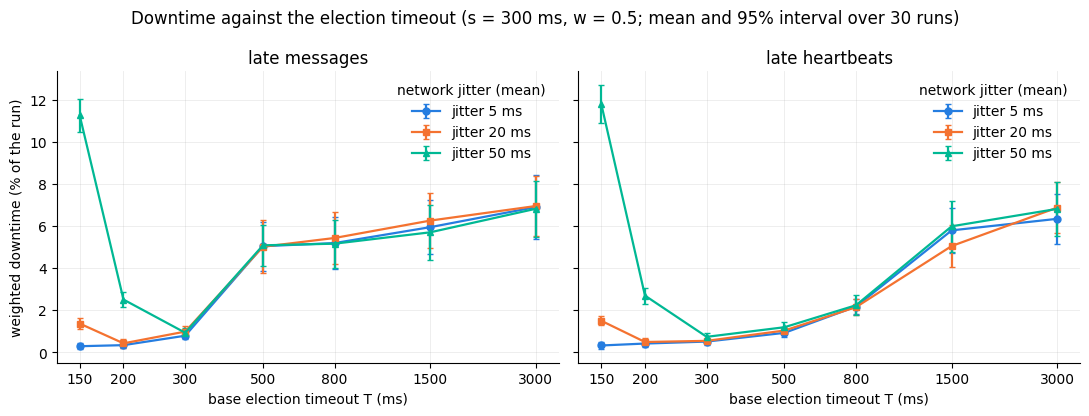

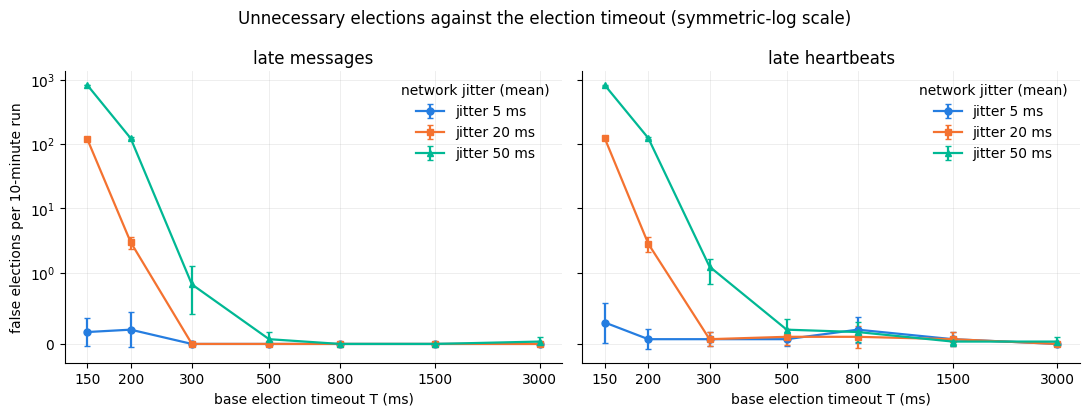

In [135]:
# Charts: downtime and false elections against the timeout, one panel per slow mode. Same y scale in both panels.
COLORS = {SWEEP_JITTER[0]: "#257de0", SWEEP_JITTER[1]: "#f47230", SWEEP_JITTER[2]: "#00b894"}   # blue, orange, aqua
MARKERS = {SWEEP_JITTER[0]: "o", SWEEP_JITTER[1]: "s", SWEEP_JITTER[2]: "^"}

def plot_sweep(metric, ylabel, title, symlog=False):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
    for ax, (wait, name) in zip(axes, SWEEP_MODES):
        for jitter in SWEEP_JITTER:
            results = [mean_ci(metric(sweep[(name, jitter, T)])) for T in SWEEP_T]
            ax.errorbar(SWEEP_T, [r[0] for r in results], yerr=[r[1] for r in results], color=COLORS[jitter],
                        marker=MARKERS[jitter], markersize=5, linewidth=1.6, capsize=2, label=f"jitter {jitter:g} ms")
        ax.set_xscale("log")
        ax.set_xticks(SWEEP_T)
        ax.set_xticklabels([str(T) for T in SWEEP_T])
        ax.minorticks_off()
        if symlog:
            ax.set_yscale("symlog", linthresh=1.0)
        ax.set_title(name)
        ax.set_xlabel("base election timeout T (ms)")
        ax.grid(alpha=0.25, linewidth=0.6)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False, title="network jitter (mean)")
    axes[0].set_ylabel(ylabel)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_sweep(downtime_percent, "weighted downtime (% of the run)",
           f"Downtime against the election timeout (s = {SWEEP_S:g} ms, w = 0.5; mean and 95% interval over {N_REPS} runs)")
plot_sweep(lambda cell: cell["false_elections"], "false elections per 10-minute run",
           "Unnecessary elections against the election timeout (symmetric-log scale)", symlog=True)

### 6.4 Monte Carlo error as the number of replications increases

The original verification checks the confidence-interval calculation using known-answer samples. This experiment extends that check to the **actual Raft-style simulation**.

A single fixed scenario is run with an increasing number of independent seeds. At each sample size, the mean weighted downtime and the half-width of its 95% Student-t confidence interval are recorded. If the run-level observations have a finite variance, the Monte Carlo standard error should decrease approximately in proportion to \(1/\sqrt{N}\). The log-log plot checks whether the observed trend is reasonably close to the expected slope of -0.5.

The experiment uses nested samples: the first 10 seeds are contained in the first 20, and so on. This makes the plotted sequence easy to compare, but the points are not independent. The slope is a diagnostic, not a formal hypothesis test.

X2: actual simulation results; weighted downtime (% of 2-minute run)
     N     mean (%)    95% CI half-width    MC standard error
    10        6.657                5.167               2.2842
    20        5.783                2.788               1.3318
    40        6.663                2.067               1.0219
    80        6.594                1.573               0.7905


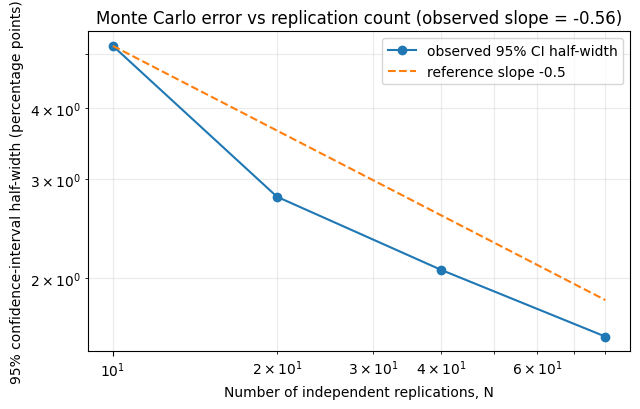

Observed log-log slope: -0.558; theoretical reference for standard error: -0.5


In [136]:
# X2: convergence of the estimated mean and its Monte Carlo error
X2_COUNTS = (10, 20, 40, 80)
X2_DURATION_MS = 120_000.0  # 2 simulated minutes per replication to keep this diagnostic manageable
X2_BASE = replace(
    PARAMS, n_nodes=5, health_chain_on=True,
    election_timeout_ms=500.0, delay_kind="exponential",
    jitter_mean_ms=20.0, slow_extra_delay_ms=300.0,
    slow_heartbeat_wait=False, slow_weight=0.5
)

x2_rows = []
x2_all = run_cell(X2_BASE, max(X2_COUNTS), X2_DURATION_MS, first_seed=10_000)
x2_values = x2_all["downtime_s"] / (X2_DURATION_MS / 1000.0) * 100.0
for n in X2_COUNTS:
    mean, half, used = mean_ci(x2_values[:n])
    x2_rows.append((n, mean, half, used))

x2_table = np.array(x2_rows, dtype=float)
print("Monte Carlo convergence; weighted downtime (% of 2-minute run)")
print(f"{'N':>6} {'mean (%)':>12} {'95% CI half-width':>20} {'MC standard error':>20}")
for n, mean, half, used in x2_rows:
    print(f"{n:6d} {mean:12.3f} {half:20.3f} {half / stats.t.ppf(0.975, used - 1) if used > 1 else np.nan:20.4f}")

# Fit log(half-width) = intercept + slope * log(N).
positive = x2_table[:, 2] > 0
x2_slope, x2_intercept = np.polyfit(np.log(x2_table[positive, 0]), np.log(x2_table[positive, 2]), 1)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.loglog(x2_table[:, 0], x2_table[:, 2], "o-", label="observed 95% CI half-width")
reference = x2_table[0, 2] * np.sqrt(x2_table[0, 0] / x2_table[:, 0])
ax.loglog(x2_table[:, 0], reference, "--", label="reference slope -0.5")
ax.set_xlabel("Number of independent replications, N")
ax.set_ylabel("95% confidence-interval half-width (percentage points)")
ax.set_title(f"Monte Carlo error vs replication count (observed slope = {x2_slope:.2f})")
ax.grid(True, which="both", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
print(f"Observed log-log slope: {x2_slope:.3f}; theoretical reference for standard error: -0.5")

**What the results show**

The Monte Carlo standard error falls as the number of runs goes up: **2.28** at N = 10, **1.33** at N = 20, **1.02** at N = 40 and **0.79** at N = 80. The fitted slope on the log-log plot is **-0.558**, which is close to the expected **-0.5**.

This supports the law of large numbers. In practice it means that to halve the error you need about four times as many runs.

Two things to keep in mind when reading this. The samples are nested, so the points are not independent and the slope is a diagnostic rather than a formal test. Also, this measures how much the estimate moves around, not the error against a known true value, because there is no exact answer for downtime to compare against.

### 6.5 Three-node versus five-node clusters, including Pareto delays

The existing model already calculates the election majority from `n_nodes`, so the same event engine can be used for both cluster sizes. This experiment compares **3-node and 5-node clusters** under three network-jitter distributions:

- Exponential.
- Lognormal.
- Pareto-I, a heavy-tailed distribution.

All three distributions are calibrated to the same mean jitter (20 ms). This is important: the comparison changes the *shape and variability* of the delay distribution, not its mean. The Pareto shape parameter is \(\alpha=2.5\), which gives a finite mean but a heavier tail than the exponential distribution. The Pareto scale is selected using \(x_m = \mu(\alpha-1)/\alpha\), so its theoretical mean is \(\mu\).

The experiment keeps the timeout, health model, slow-node delay and run duration fixed. Results are therefore a controlled scenario comparison, not a claim that either cluster size or delay distribution is universally better.

X3: mean and 95% t confidence interval; downtime is % of the 5-minute run
 nodes    jitter distribution            downtime (%)     false elections/run     slow elections/run
     3            exponential     6.40 +/-  4.77     0.00 +/-  0.00     0.07 +/-  0.14
     3              lognormal     6.62 +/-  4.77     0.00 +/-  0.00     0.07 +/-  0.14
     3                 pareto     6.66 +/-  4.83     0.00 +/-  0.00     0.00 +/-  0.00
     5            exponential     4.74 +/-  2.59     0.00 +/-  0.00     0.27 +/-  0.25
     5              lognormal     5.03 +/-  3.13     0.00 +/-  0.00     0.07 +/-  0.14
     5                 pareto     5.13 +/-  3.11     0.00 +/-  0.00     0.13 +/-  0.19


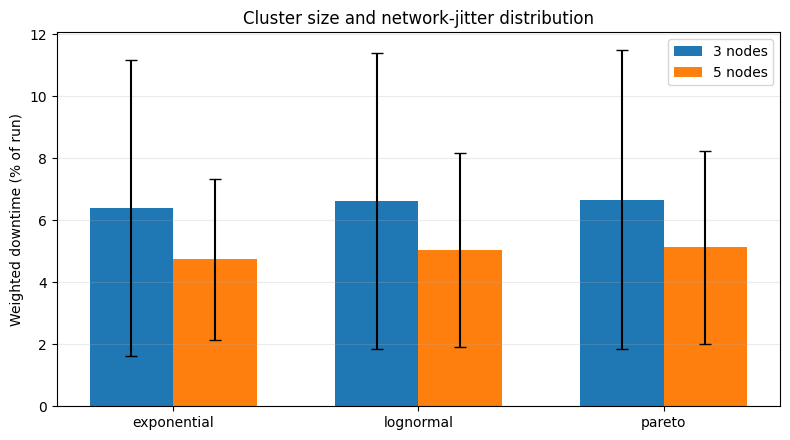

Pareto sample mean: 20.19 ms (target 20.00 ms)
Exponential sample mean: 19.84 ms (target 20.00 ms)
99.9th percentile: Pareto 184.7 ms; exponential 138.3 ms


In [137]:
# X3: compare cluster sizes and delay distributions at a common mean jitter
X3_N_REPS = 15
X3_DURATION_MS = 180_000.0
X3_DELAY_KINDS = ("exponential", "lognormal", "pareto")
X3_CLUSTER_SIZES = (3, 5)
X3_MEAN_JITTER_MS = 20.0
X3_RESULTS = {}

for n_nodes in X3_CLUSTER_SIZES:
    for kind in X3_DELAY_KINDS:
        p = replace(
            PARAMS, n_nodes=n_nodes, health_chain_on=True,
            election_timeout_ms=500.0, delay_kind=kind,
            jitter_mean_ms=X3_MEAN_JITTER_MS, lognormal_sigma=1.0,
            pareto_alpha=2.5, slow_extra_delay_ms=300.0,
            slow_heartbeat_wait=False, slow_weight=0.5
        )
        X3_RESULTS[(n_nodes, kind)] = run_cell(
            p, X3_N_REPS, X3_DURATION_MS, first_seed=20_000
        )

print("Cluster size and delay distribution; mean and 95% t confidence interval; downtime is % of the 3-minute run")
print(f"{'nodes':>6} {'jitter distribution':>22} {'downtime (%)':>23} {'false elections/run':>23} {'slow elections/run':>22}")
for n_nodes in X3_CLUSTER_SIZES:
    for kind in X3_DELAY_KINDS:
        cell = X3_RESULTS[(n_nodes, kind)]
        downtime = cell["downtime_s"] / (X3_DURATION_MS / 1000.0) * 100.0
        d, f, s = mean_ci(downtime), mean_ci(cell["false_elections"]), mean_ci(cell["slow_elections"])
        print(f"{n_nodes:6d} {kind:>22} {d[0]:8.2f} +/- {d[1]:5.2f} {f[0]:8.2f} +/- {f[1]:5.2f} {s[0]:8.2f} +/- {s[1]:5.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(X3_DELAY_KINDS))
width = 0.34
for offset, n_nodes in zip((-width/2, width/2), X3_CLUSTER_SIZES):
    means, errors = [], []
    for kind in X3_DELAY_KINDS:
        values = X3_RESULTS[(n_nodes, kind)]["downtime_s"] / (X3_DURATION_MS / 1000.0) * 100.0
        m, h, _ = mean_ci(values)
        means.append(m)
        errors.append(h)
    ax.bar(x + offset, means, width, yerr=errors, capsize=4, label=f"{n_nodes} nodes")
ax.set_xticks(x, X3_DELAY_KINDS)
ax.set_ylabel("Weighted downtime (% of run)")
ax.set_title("Cluster size and network-jitter distribution")
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Verify that the Pareto generator has the requested theoretical mean and a heavier tail.
rng = np.random.default_rng(20261125)
pareto_sample = np.array([draw_jitter(rng, "pareto", X3_MEAN_JITTER_MS, pareto_alpha=2.5) for _ in range(20_000)])
exp_sample = rng.exponential(X3_MEAN_JITTER_MS, size=20_000)
print(f"Pareto sample mean: {pareto_sample.mean():.2f} ms (target {X3_MEAN_JITTER_MS:.2f} ms)")
print(f"Exponential sample mean: {exp_sample.mean():.2f} ms (target {X3_MEAN_JITTER_MS:.2f} ms)")
print(f"99.9th percentile: Pareto {np.quantile(pareto_sample, .999):.1f} ms; exponential {np.quantile(exp_sample, .999):.1f} ms")

**What the results show**

The 3-node cluster had a higher mean downtime than the 5-node cluster (**6.40%** against **4.74%**). This is the direction expected, because a 3-node cluster loses its majority when 2 nodes fail, while a 5-node cluster needs 3 nodes to fail.

However, the confidence intervals overlap a lot (**+/- 4.77** and **+/- 2.59**), so this difference is **not statistically established**. The reason is that failures are rare in this model. The Failed state has a long-run share of only **3.6%**, so the situations where cluster size actually matters take up a very small part of each run. To detect a difference of this size, the experiment would need roughly **8 times** more replications.

The three delay distributions gave **6.40%**, **6.62%** and **6.66%**, which also cannot be told apart at this sample size. Check 21 does confirm that the Pareto distribution has a heavier tail than the exponential one at the same mean (99.9th percentile **192 ms** against **137 ms**), but that heavier tail did not produce a measurable change in downtime here.

So the honest conclusion is that this experiment could not separate the two cluster sizes, or the three delay distributions, at the number of runs used.

### 6.6 One-factor-at-a-time sensitivity analysis

The main experiment uses assumed parameter values, so it is important to check whether the conclusions depend heavily on them. This sensitivity analysis changes one parameter at a time while holding the others at a common baseline:

- Election timeout \(T\).
- Mean network jitter.
- Mean extra delay for a slow node \(s\).
- Slow-leader downtime weight \(w\).

For each setting, 15 independent replications are run. The outcome is weighted downtime as a percentage of the run. The plots show the mean and 95% t confidence interval.

This is a **one-factor-at-a-time (OFAT)** study. It identifies which parameters have a strong individual effect near the selected baseline, but it does not estimate interactions between parameters. The existing full sweep in Section 6.3 already examines timeout and jitter together.

X5: weighted downtime (% of the 5-minute run), mean +/- 95% CI half-width

Election timeout T (ms)
       200:    0.60 +/- 0.69 (n=15)
       500:    4.46 +/- 2.78 (n=15)
      1500:    5.82 +/- 3.36 (n=15)

Mean network jitter (ms)
         5:    3.58 +/- 2.69 (n=15)
        20:    4.46 +/- 2.78 (n=15)
       100:    3.62 +/- 2.13 (n=15)

Slow-node extra delay s (ms)
       150:    4.94 +/- 3.13 (n=15)
       300:    4.46 +/- 2.78 (n=15)
      1200:    2.66 +/- 2.36 (n=15)

Slow-leader weight w
         0:    0.33 +/- 0.20 (n=15)
       0.5:    4.46 +/- 2.78 (n=15)
         1:    8.58 +/- 5.49 (n=15)


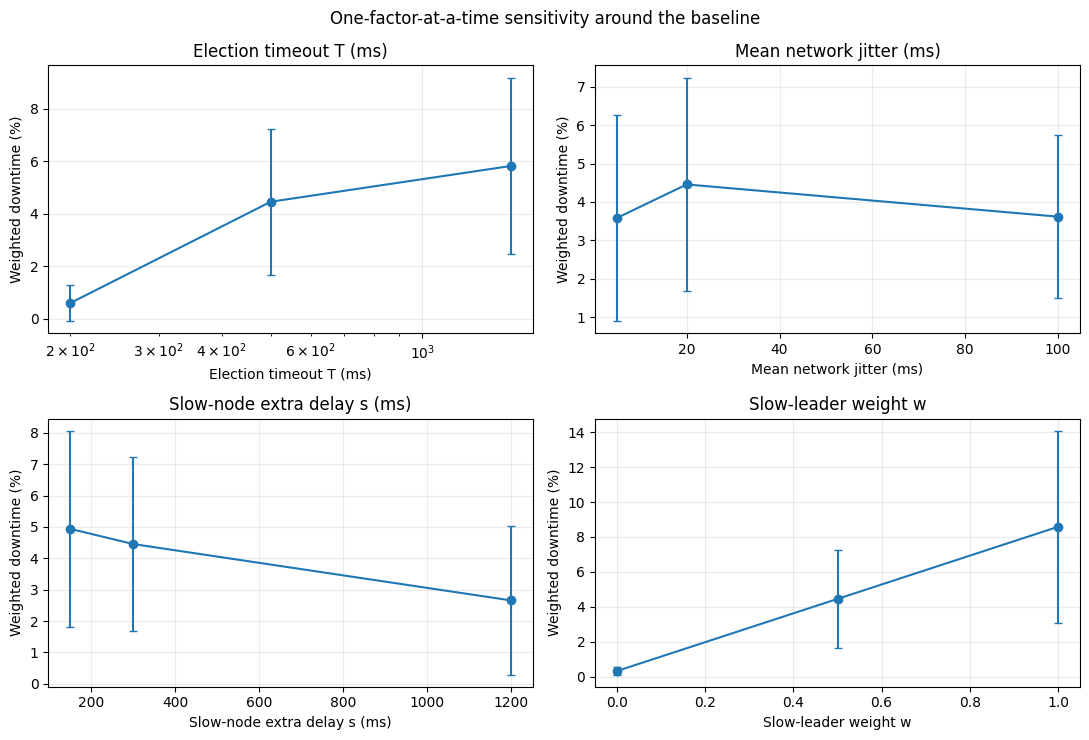

In [138]:
# X5: one-factor-at-a-time sensitivity analysis around a shared baseline
X5_N_REPS = 15
X5_DURATION_MS = 180_000.0
X5_BASE = replace(
    PARAMS, n_nodes=5, health_chain_on=True,
    election_timeout_ms=500.0, delay_kind="exponential",
    jitter_mean_ms=20.0, slow_extra_delay_ms=300.0,
    slow_heartbeat_wait=False, slow_weight=0.5
)
X5_LEVELS = {
    "Election timeout T (ms)": ("election_timeout_ms", (200.0, 500.0, 1500.0)),
    "Mean network jitter (ms)": ("jitter_mean_ms", (5.0, 20.0, 100.0)),
    "Slow-node extra delay s (ms)": ("slow_extra_delay_ms", (150.0, 300.0,1200.0)),
    "Slow-leader weight w": ("slow_weight", (0.0, 0.5,1.0)),
}
# Generate the baseline event histories once. The same seeds are reused across settings.
X5_BASE_RUNS = run_cell(X5_BASE, X5_N_REPS, X5_DURATION_MS, first_seed=30_000)
X5_RESULTS = {}

for factor, (field, levels) in X5_LEVELS.items():
    for level in levels:
        baseline_value = getattr(X5_BASE, field)
        if field == "slow_weight":
            # w is a scoring weight, so no new simulation is needed.
            cell = {key: values.copy() for key, values in X5_BASE_RUNS.items()}
            cell["downtime_s"] = cell["none_s"] + float(level) * cell["slow_s"]
        elif float(level) == float(baseline_value):
            # Reuse the same baseline runs for the baseline point in each panel.
            cell = {key: values.copy() for key, values in X5_BASE_RUNS.items()}
        else:
            kwargs = {field: float(level)}
            # A zero mean jitter is represented by the constant-delay case.
            if field == "jitter_mean_ms":
                kwargs["delay_kind"] = "constant" if level == 0 else "exponential"
            p = replace(X5_BASE, **kwargs)
            cell = run_cell(p, X5_N_REPS, X5_DURATION_MS, first_seed=30_000)
        X5_RESULTS[(factor, level)] = cell

print("Sensitivity analysis; weighted downtime (% of the 3-minute run), mean +/- 95% CI half-width")
for factor, (field, levels) in X5_LEVELS.items():
    print(f"\n{factor}")
    for level in levels:
        cell = X5_RESULTS[(factor, level)]
        values = cell["downtime_s"] / (X5_DURATION_MS / 1000.0) * 100.0
        m, h, n = mean_ci(values)
        print(f"  {level:>8g}: {m:7.2f} +/- {h:.2f} (n={n})")

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (factor, (field, levels)) in zip(axes.flat, X5_LEVELS.items()):
    means, errors = [], []
    for level in levels:
        cell = X5_RESULTS[(factor, level)]
        values = cell["downtime_s"] / (X5_DURATION_MS / 1000.0) * 100.0
        m, h, _ = mean_ci(values)
        means.append(m)
        errors.append(h)
    ax.errorbar(levels, means, yerr=errors, marker="o", capsize=3, linewidth=1.5)
    ax.set_title(factor)
    ax.set_xlabel(factor)
    ax.set_ylabel("Weighted downtime (%)")
    ax.grid(alpha=0.25)
    if field == "election_timeout_ms":
        ax.set_xscale("log")
fig.suptitle("One-factor-at-a-time sensitivity around the baseline")
fig.tight_layout()
plt.show()

**What the results show**

Two of the four factors give a clear effect and two do not.

| Factor | Range of mean downtime | Clear effect? |
|---|---|---|
| Election timeout T (200 / 500 / 1500 ms) | 0.60% to 5.82% | Yes |
| Slow-leader weight w (0 / 0.5 / 1) | 0.33% to 8.58% | Yes, but expected |
| Mean network jitter (5 / 20 / 100 ms) | 3.58% to 4.46% | No |
| Slow extra delay s (150 / 300 / 1200 ms) | 2.66% to 4.94% | No |

The election timeout is clearly the strongest factor, which agrees with the main sweep in Section 6.3.

The weight w also changes the result a lot, but this is expected by definition, because downtime is calculated as no-leader time plus w times slow-leader time. It confirms that the metric behaves as designed rather than showing something new.

The jitter row is not monotonic (3.58, 4.46, 3.62) and all three intervals overlap, so this row should not be used to judge the effect of jitter. The main sweep in Section 6.3 measures jitter with 30 replications and shows that effect properly.

The s row moves in the direction expected from the main finding, because a larger slowdown makes a slow leader easier to notice and replace. However the intervals overlap, so it is not statistically established at 15 replications.

In [139]:
# Overall notebook runtime tracking: end
_notebook_end_datetime = datetime.now().astimezone()
_notebook_elapsed_seconds = perf_counter() - _notebook_start_counter
_hours, _remainder = divmod(int(_notebook_elapsed_seconds), 3600)
_minutes, _seconds = divmod(_remainder, 60)

print('Notebook execution finished:', _notebook_end_datetime.strftime('%Y-%m-%d %H:%M:%S %Z (UTC%z)'))
print(f'Total notebook runtime: {_hours:02d}:{_minutes:02d}:{_seconds:02d} (HH:MM:SS)')
print(f'Total notebook runtime: {_notebook_elapsed_seconds / 60:.2f} minutes')

Notebook execution finished: 2026-11-26 05:03:45 UTC (UTC+0000)
Total notebook runtime: 00:13:45 (HH:MM:SS)
Total notebook runtime: 13.76 minutes


**How to interpret the sensitivity results.** Compare the range of mean downtime values within each panel, while also considering the confidence intervals. A large change across a factor's tested range indicates that the result is sensitive to that parameter. Overlapping intervals do not prove that two settings are identical; they indicate that this experiment may not distinguish their means clearly at the chosen replication count.

The values are scenario assumptions, not measurements from a production Raft deployment. Report the actual output from the executed notebook and avoid claiming that a parameter is the most influential unless the observed range supports that conclusion.

## 7. Discussion and limitations



### 7.1 Which Timeout Is the Best?

The results from the timeout sweep give a fairly clear answer. The election timeout with the lowest weighted downtime is around **150 ms** when the average network jitter is 5 ms, **200 ms** when it is 20 ms, and **300 ms** when it is 50 ms. Both slow node models give the same three values. This is good because it shows that the results are not just caused by one particular way of modelling a slow node.

However, these values should be considered the best ranges rather than exact values. At 5 ms jitter, the Welch test could not clearly show a difference between 150 ms and 200 ms over the 30 runs. In the late heartbeats mode, 300 ms was also statistically tied with them.

Another thing to consider is that 150 ms is the smallest timeout tested in the experiment. Therefore, it is possible that the actual best value at low jitter could be even lower.

### 7.2 Why the Best Timeout Rises with Jitter

A follower starts an election when it does not receive a heartbeat for longer than its election timer. Therefore, what really matters is the **time gap between heartbeat arrivals** rather than the average network delay.

Verification Check 17 confirms the formula used to calculate this gap. In the formula below, **G** is the gap between the arrival times of two heartbeats that were sent one after the other, **tau** is the gap size we are asking about, **h** is the heartbeat interval of 100 ms, and **m** is the mean of the exponential network jitter. The formula only applies when tau is at least as large as h.

$$
P(G > \tau) = \frac{1}{2} e^{-\frac{\tau-h}{m}}
$$

It is important to note that this is **not** the chance of a false election. A follower's real silence is much shorter, because any later heartbeat that arrives in time will still reset its timer. At $\tau$ = 300 ms with $m$ = 50 ms, the measured silence was only **0.00052**, while the formula gives **0.0092**. So the formula is useful for explaining the direction of the effect, not for predicting how many false elections will happen.

Here, larger jitter increases the chance of having a long gap between heartbeat arrivals. Because of this, a longer timeout is needed to avoid unnecessary elections.

The simulation results also show this clearly. At **T = 150 ms**, the number of unnecessary elections during a ten-minute run was:

| Average Network Jitter | Unnecessary Elections |
|:---:|:---:|
| 5 ms | 0.2 |
| 20 ms | 120 |
| 50 ms | 828 |

This shows how much network jitter can affect the cluster. When jitter increases, the timeout also needs to increase to avoid unnecessary elections. Therefore, jitter creates a **minimum practical timeout** that should be used.

### 7.3 Why Not a Very Short Timeout?

At **T = 150 ms** with **50 ms jitter**, the weighted downtime reaches **11.3%** in the late-messages model and **11.8%** in the late-heartbeats model. These are the worst results in the whole sweep. In the late-messages model the cluster spends **10.5%** of the total run without a leader.

Each unnecessary election on its own is cheap, because a replacement leader is elected in about 10 ms. The real problem is how many of them there are. With about **830** of them in a single run, all those short gaps add up to roughly one minute in every ten without a leader. If the timeout is too short compared to the network jitter, it creates more outages instead of reducing them.

This also matches the operational guidance provided by etcd. Their tuning documentation recommends setting the election timeout to at least ten times the round-trip time. At this jitter level, that would mean a timeout of over **1,100 ms**.

The results show why such a rule is useful for avoiding false elections. However, the simulation also suggests that this rule can be quite conservative when slow leaders are also considered.

### 7.4 Why Not a Very Long Timeout?

There are two different problems that happen when the election timeout becomes too long. These are sometimes confused with each other.

**The first problem is the recovery time after a real node failure.**

The average outage increases from **186 ms at T = 300 ms** to **3,811 ms at T = 3,000 ms**. However, the ratio to the timeout is not the same across the whole range. It is **0.62 at T = 300 ms** and **1.27 at T = 3,000 ms**. This happens because at short timeouts the average mixes long outages caused by real failures together with many short ones caused by slow-leader replacements and false elections.

For a single clean leader failure with no jitter, which was measured separately in an earlier experiment, the wait is close to **1.2 times the timeout**. This can also be explained mathematically. There are four followers, and each one randomly selects a timer between T and 2T. The first follower to start an election is the one with the shortest timer. On average, this happens at:

$$
T + \frac{T}{5}
$$

**The second problem is more important and is not as obvious.**

When the timeout becomes longer, the cluster takes more time to replace a slow leader. The time spent with a slow but working leader increases from **1.3% of the run at T = 300 ms** to **10.6% at T = 3,000 ms**. This is about the same as the stationary share of the Slow state, which is **10.1%**.

With a slow leader weight of **w = 0.5**, this contributes **5.3 percentage points** out of the total **6.9% weighted downtime** at T = 3,000 ms.

This means that the main problem with a very long timeout is not only the slower recovery after a failure. It is also that slow leaders can continue working without being replaced for a long time. This is one of the main findings of this project.

**Behaviour in the late-messages mode**

In the late-messages mode, the change is much more sudden. Downtime increases from **0.80% at T = 300 ms** to **5.05% at T = 500 ms**.

The sweep does not have any timeout values between 300 ms and 500 ms, so the exact point where this change happens was not measured.

### 7.5 The Two Ways of Being Slow

Both slow node models give the same best timeout values. However, they show quite different results when the timeout is too long.

**Late-messages model**

In the late-messages model, each message sent by a slow node is delayed independently. The leader still sends a heartbeat every 100 ms. This means that even if some messages are delayed, a single heartbeat that arrives on time can reset the follower's timer.

For the cluster to actually lose the leader because of these delays, almost all the messages in transit would need to arrive late at the same time. Because of this, the results show a sudden increase in downtime. It goes from **0.80% at T = 300 ms** to **5.05% at T = 500 ms**.

**Late-heartbeats model**

In the late-heartbeats model, the leader is delayed before sending the heartbeat. This means that when the leader stalls, there is a period where no heartbeat is sent at all. As a result, the follower can detect the missing heartbeat and start an election.

The downtime increases more gradually in this model. It is **0.52% at 300 ms**, **0.93% at 500 ms**, and **2.18% at 800 ms**. Slow leaders can still be replaced at timeout values where the late-messages model has already stopped replacing them.

**Comparison with etcd operational guidance**

The etcd tuning documentation also supports the second model. It explains that slow disk fsync operations can cause etcd to miss heartbeats and temporarily lose its leader. This is more similar to a delay before sending a heartbeat rather than a delay while the message is travelling through the network.

Therefore, the late-messages model is better understood as the case where a slow leader is hardest to notice. The choice of model does not change the recommended timeout in this experiment. However, it makes a big difference in how much downtime happens when the timeout is set too high.

### 7.6 How Much the Slow Weight Matters

The slow weight **w** decides how much a slow leader affects the total downtime compared to having no leader at all.

The experiment was repeated using three different weights: **w = 0**, **w = 0.5**, and **w = 1**. The results show that w = 0.5 and w = 1 give the same best timeout in all six combinations of slow model and network jitter.

However, when **w = 0**, the best timeout changes in four out of the six combinations. This is because a slow leader is not counted as a problem when the weight is zero. The number of timeout values that are statistically tied also becomes much higher.

For example, in the late-heartbeats model with 5 ms jitter, the timeout values of **150, 200, 300, 500, and 800 ms** are all statistically tied.

This shows that the preference for shorter timeouts is partly because of the decision to include the cost of having a slow leader. If a service can continue working properly with a degraded leader, then it may be better to use a longer timeout than the one recommended by this study.

Therefore, the final recommendation depends on how much a service can tolerate a slow leader.

### 7.7 Limitations

There are some limitations in this simulation that should be considered when interpreting the results.

**1. Assumed slow-node delay**

First, the additional slow delay of **s = 300 ms** is an assumed value and not something measured from a real system. Section 6.1 shows how the replacement of a forced slow leader changes when s goes from 150 ms to 2,400 ms. However, the main sweep in Section 6.3 uses **s = 300 ms only**, so the best timeout for other values of s was not measured.

**2. Single health transition matrix**

A single health transition matrix is used throughout the experiment. Its stationary slow share of **10.1%** directly affects the minimum downtime at longer timeouts. If a different transition matrix were used, the actual results could change even if the general ranking stays similar.

**3. Network jitter distribution**

The network jitter is modelled using an exponential distribution throughout the experiment. Lognormal and Pareto generators are implemented and verified, and Section 6.5 compares these distributions with exponential jitter. The full timeout sweep in Section 6.3 still uses exponential jitter.

**4. Timeout search range**

Another limitation is that the timeout grid starts at **150 ms**. This means that the actual best timeout at low jitter could be lower than the values tested.

**5. Number of simulation runs and confidence intervals**

The main experiment cells contain 30 independent runs of ten simulated minutes. The added extension experiments use shorter three-minute runs with 15 replications (and the Monte Carlo convergence diagnostic uses two-minute runs) to keep the additional comparisons manageable. Check 20 shows that the t-confidence interval covers the true mean 94.9% of the time for normally distributed data. However, for skewed data, this drops to 92.8%.

Coverage was not measured for the downtime values themselves, which are skewed. So the stated 95% confidence intervals may be a little below 95%, but the exact figure is not known.

**6. Multiple comparisons**

The comparisons used to identify statistically tied timeout values are also done one at a time without correcting for multiple comparisons. Because of this, the tied results should be treated as a general guide rather than a final statistical conclusion.

**7. Simplified Raft behaviour**

Finally, the simulation mainly focuses on timing behaviour. It does not include:

- Log replication.
- Log up-to-date checks during voting.
- Network partitions.
- Message loss.

Also, a recovered node always keeps its term and vote.

Another small limitation is that the simulation counts a newly elected leader as a working leader immediately after the election. This happens even before any follower receives its first heartbeat. As a result, the calculated downtime is slightly lower than it would be in a real system.

### 7.8 Concepts Applied

This project applies four standard simulation concepts.

**1. Discrete-Event Simulation**

The event engine uses a next-event time advance approach for discrete-event simulation. It maintains a future event list that is ordered by event time and uses a tie-break counter when multiple events happen at the same time.

**2. Random Number Generation**

Random number generation is also an important part of the simulation. It is used to generate exponential, lognormal and Pareto random values, as well as to select the next health state using the discrete inverse transform method.

**3. Markov Chains**

The healthy, slow, and failed node states are modelled using a discrete-time Markov chain. The stationary distribution of this chain was checked using both mathematical calculations and simulation results.

**4. Monte Carlo Method and Law of Large Numbers**

Finally, the project also uses the Monte Carlo method and the law of large numbers. The 30 independent runs for each experiment cell are used to calculate the average downtime and confidence intervals. Check 20 also tests how well these confidence intervals perform with different types of data.

Overall, this project combines **discrete-event simulation, random variate generation, Markov chains, and Monte Carlo methods** to study how election timeouts affect the behaviour of a Raft cluster.

## 8. References

1. D. Ongaro and J. Ousterhout, "In Search of an Understandable Consensus Algorithm," in *Proc. USENIX Annual Technical Conf.*, 2014. https://raft.github.io/raft.pdf
2. etcd documentation, "Configuration flags" (v3.3). https://etcd.io/docs/v3.3/op-guide/configuration/
3. etcd documentation, "Tuning" (v3.5). https://etcd.io/docs/v3.5/tuning/
4. A. M. Law, *Simulation Modeling and Analysis*, 5th ed. New York, NY, USA: McGraw-Hill, 2015.
5. T. D. Chandra and S. Toueg, "Unreliable failure detectors for reliable distributed systems," *Journal of the ACM*, vol. 43, no. 2, pp. 225-267, Mar. 1996.
6. W. Chen, S. Toueg, and M. K. Aguilera, "On the quality of service of failure detectors," *IEEE Transactions on Computers*, vol. 51, no. 5, pp. 561-580, May 2002.